# Практична робота №5
## Нейронна мережа NumPy та дослідження регуляризації

Студент: Панчишин Володимир

**Мета:** Самостійно реалізувати прямий прохід, backpropagation і SGD та дослідити L1, L2, Dropout і clipping на Fashion-MNIST.

Джерело завдання: https://github.com/olehsinkevych/machine-learning

**Відтворення:** середовище Python 3.12, залежності в requirements.txt; перед запуском усієї роботи завантажте дані командою `python download_data.py`. Усі результати нижче отримуються виконанням коду, а не копіюванням готових таблиць.

In [1]:
from pathlib import Path
import sys, os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'project' / 'common.py').is_file())
sys.path.insert(0, str(ROOT / 'project'))
import common
from IPython.display import display, Image
import pandas as pd
import json

## 1. Теоретичні пояснення та відповіді на питання

### Мережа та backpropagation
Архітектура 784-64-48-32-10 має три приховані ReLU-шари та вихід Softmax. Ваги ініціалізовано за He. Для CE і Softmax вихідний градієнт дорівнює (P-Y)/m; далі він множиться на транспоновані ваги та похідну ReLU. Уся реалізація навчання виконується NumPy, без autograd і готових нейромереж.

### Контрольований експеримент
Усі 13 конфігурацій мають однакові Train/Validation, початкові ваги, порядок батчів, 30 епох, batch=128 і learning rate=0,05. Порівнюється фінальний стан після однакового числа епох. Test використовується лише для конфігурації з найменшою фінальною Validation CE. Функція втрат у порівняльній таблиці не включає регуляризаційний штраф, щоб шкали були однакові.

### L1, L2 і Dropout
L1 додає λ₁Σ|W| та субградієнт λ₁sign(W); у точці нуля використано 0. L2 додає λ₂ΣW²/2 та градієнт λ₂W. Штрафи застосовано лише до ваг, не до bias. Inverted Dropout ділить збережені активації на 1-p під час навчання; у validation, test і діагностиці нейронів випадкову маску вимкнено.

### Два різні clipping
Weight clipping обмежує самі ваги інтервалом [-1,1] після оновлення. Gradient clipping обмежує одну глобальну L2-норму всіх градієнтів ваг і bias; відповідно однаково масштабує весь градієнт. Це не додатковий штраф у функції втрат. Такі операції можуть стабілізувати навчання, але надто сильний clipping уповільнює його.

### Малі ваги та мертві нейрони
Sparsity означає частку всіх ваг із |w|<0,01. Мертвим вважаю прихований нейрон, передактивація якого не є додатною для жодного навчального прикладу в inference-режимі. Неактивність на одному прикладі, випадкове вимкнення Dropout і мертвість на всій вибірці - різні поняття. Це емпірична мертвість на Train, а не доказ неактивності в усьому просторі входів.

### Перевірка та серіалізація
Backpropagation перевірено центральними скінченними різницями в double precision. NPZ містить архітектуру, параметри ініціалізації, конфігурацію, усі W і b; відновлення не потребує pickle. Порівнюю ймовірності та класи початкової й завантаженої моделі. Сильніша регуляризація не завжди покращує узагальнення: надто великі штрафи або Dropout можуть спричинити недонавчання.

## 2. Повна реалізація

Далі міститься власна реалізація обчислень цієї роботи. Код також винесено в окремий файл `project/lab05.py`.

In [2]:
"""Практична 5: MLP, backpropagation та регуляризація, лише NumPy."""

import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from common import (
    folder,
    savefig,
    dump,
    image_data,
    numerical_gradient,
    classification,
    cm_plot,
)

In [3]:
class MLP:
    def __init__(
        self,
        widths=(784, 64, 48, 32, 10),
        seed=42,
        l1=0.0,
        l2=0.0,
        dropout=0.0,
        weight_clip=None,
        gradient_clip=None,
        dtype=np.float32,
    ):
        self.widths = list(widths)
        self.seed = seed
        self.l1 = l1
        self.l2 = l2
        self.dropout = dropout
        self.weight_clip = weight_clip
        self.gradient_clip = gradient_clip
        self.dtype = dtype
        rng = np.random.default_rng(seed)
        self.rng = np.random.default_rng(seed + 1000)
        self.weights = [
            (rng.normal(size=(a, b)) * np.sqrt(2 / a)).astype(dtype)
            for a, b in zip(widths[:-1], widths[1:])
        ]
        self.biases = [np.zeros(b, dtype=dtype) for b in widths[1:]]
        self.clip_steps = 0
        self.steps = 0

    def forward(self, x, training=False):
        self.activations = [x]
        self.z_values = []
        self.masks = []
        a = x
        for w, b in zip(self.weights[:-1], self.biases[:-1]):
            z = a @ w + b
            a = np.maximum(z, 0)
            mask = None
            if training and self.dropout:
                mask = (self.rng.random(a.shape) >= self.dropout).astype(self.dtype) / (
                    1 - self.dropout
                )
                a = a * mask
            self.z_values.append(z)
            self.activations.append(a)
            self.masks.append(mask)
        z = a @ self.weights[-1] + self.biases[-1]
        z -= z.max(1, keepdims=True)
        exp = np.exp(z)
        p = exp / exp.sum(1, keepdims=True)
        self.z_values.append(z)
        self.activations.append(p)
        return p

    def loss(self, x, y, regularized=True):
        self.forward(x)
        z = self.z_values[-1]
        loss = np.mean(np.log(np.exp(z).sum(1)) - z[np.arange(len(y)), y])
        if regularized:
            loss += self.l1 * sum(
                np.abs(w).sum() for w in self.weights
            ) + self.l2 / 2 * sum((w * w).sum() for w in self.weights)
        return float(loss)

    def backward(self, y):
        delta = self.activations[-1].copy()
        delta[np.arange(len(y)), y] -= 1
        delta /= len(y)
        gw = [None] * len(self.weights)
        gb = [None] * len(self.biases)
        for layer in reversed(range(len(self.weights))):
            gw[layer] = (
                self.activations[layer].T @ delta
                + self.l1 * np.sign(self.weights[layer])
                + self.l2 * self.weights[layer]
            )
            gb[layer] = delta.sum(0)
            if layer:
                delta = delta @ self.weights[layer].T
                if self.masks[layer - 1] is not None:
                    delta *= self.masks[layer - 1]
                delta *= self.z_values[layer - 1] > 0
        return gw, gb

    def step(self, x, y, lr):
        self.forward(x, training=True)
        gw, gb = self.backward(y)
        norm = np.sqrt(sum(float(np.sum(g.astype(np.float64) ** 2)) for g in gw + gb))
        factor = 1.0
        if self.gradient_clip is not None:
            factor = min(1, self.gradient_clip / max(norm, 1e-12))
        self.clip_steps += int(factor < 1)
        self.steps += 1
        for j in range(len(self.weights)):
            self.weights[j] -= lr * factor * gw[j]
            self.biases[j] -= lr * factor * gb[j]
            if self.weight_clip is not None:
                np.clip(
                    self.weights[j],
                    -self.weight_clip,
                    self.weight_clip,
                    out=self.weights[j],
                )

    def predict_proba(self, x):
        return np.concatenate(
            [self.forward(x[i : i + 512]).copy() for i in range(0, len(x), 512)]
        )

    def diagnose(self, x):
        maxima = [np.full(b, -np.inf) for b in self.widths[1:-1]]
        for start in range(0, len(x), 512):
            self.forward(x[start : start + 512], training=False)
            for j, z in enumerate(self.z_values[:-1]):
                maxima[j] = np.maximum(maxima[j], z.max(0))
        dead = [int((m <= 0).sum()) for m in maxima]
        sizes = self.widths[1:-1]
        return {
            "dead_per_layer": dead,
            "dead_percent_per_layer": [100 * d / n for d, n in zip(dead, sizes)],
            "dead_percent": 100 * sum(dead) / sum(sizes),
            "sparsity_percent": 100
            * sum(int((abs(w) < 0.01).sum()) for w in self.weights)
            / sum(w.size for w in self.weights),
            "weights_at_boundary": sum(
                int(np.isclose(abs(w), 1, atol=1e-7).sum()) for w in self.weights
            ),
            "gradient_clipped_steps": self.clip_steps,
            "total_steps": self.steps,
        }

    def save(self, path):
        config = {
            k: getattr(self, k)
            for k in [
                "widths",
                "seed",
                "l1",
                "l2",
                "dropout",
                "weight_clip",
                "gradient_clip",
            ]
        }
        config["dtype"] = np.dtype(self.dtype).name
        data = {"config": np.array(json.dumps(config))}
        for j, (w, b) in enumerate(zip(self.weights, self.biases)):
            data[f"w{j}"] = w
            data[f"b{j}"] = b
        np.savez(path, **data)

    @classmethod
    def load(cls, path):
        with np.load(path, allow_pickle=False) as data:
            config = json.loads(str(data["config"]))
            config["dtype"] = np.dtype(config["dtype"])
            model = cls(**config)
            for j in range(len(model.weights)):
                model.weights[j] = data[f"w{j}"].copy()
                model.biases[j] = data[f"b{j}"].copy()
        return model

In [4]:
def run():
    out = folder(5)
    xall, yall = image_data("train")
    xt, yt = image_data("t10k")
    ids = np.arange(len(yall))
    subset, _ = train_test_split(ids, train_size=15000, stratify=yall, random_state=42)
    tr, va = train_test_split(
        subset, test_size=0.2, stratify=yall[subset], random_state=42
    )
    x, y = xall[tr], yall[tr]
    xv, yv = xall[va], yall[va]
    # Чисельна перевірка на малій мережі: double precision, вимкнений Dropout.
    rng = np.random.default_rng(42)
    small = MLP((4, 5, 4, 3), l2=0.003, dtype=np.float64)
    gx = rng.normal(size=(6, 4))
    gy = np.array([0, 1, 2, 0, 1, 2])
    small.forward(gx)
    gw, gb = small.backward(gy)
    grad = numerical_gradient(
        lambda: small.loss(gx, gy), small.weights + small.biases, gw + gb, count=60
    )
    configs = [
        ("Baseline", {}),
        ("L1 0.0001", {"l1": 0.0001}),
        ("L1 0.001", {"l1": 0.001}),
        ("L2 0.0001", {"l2": 0.0001}),
        ("L2 0.01", {"l2": 0.01}),
        ("Dropout 0.1", {"dropout": 0.1}),
        ("Dropout 0.2", {"dropout": 0.2}),
        ("Dropout 0.3", {"dropout": 0.3}),
        ("Dropout 0.5", {"dropout": 0.5}),
        ("Weight clip 1", {"weight_clip": 1.0}),
        ("Gradient clip 0.1", {"gradient_clip": 0.1}),
        ("Gradient clip 1", {"gradient_clip": 1.0}),
        ("L2 + Dropout 0.2", {"l2": 0.0001, "dropout": 0.2}),
    ]
    initial = MLP()
    initial_weights = [w.copy() for w in initial.weights]
    results = {}
    models = {}
    histories = {}
    for number, (name, config) in enumerate(configs):
        model = MLP(**config)
        assert all(np.array_equal(a, b) for a, b in zip(initial_weights, model.weights))
        history = []
        order_rng = np.random.default_rng(42)
        for epoch in range(30):
            ids = order_rng.permutation(len(y))
            for start in range(0, len(y), 128):
                batch = ids[start : start + 128]
                model.step(x[batch], y[batch], 0.05)
            p = model.predict_proba(x)
            pv = model.predict_proba(xv)
            row = {
                "epoch": epoch + 1,
                "train_loss": float(
                    -np.log(np.maximum(p[np.arange(len(y)), y], 1e-30)).mean()
                ),
                "validation_loss": float(
                    -np.log(np.maximum(pv[np.arange(len(yv)), yv], 1e-30)).mean()
                ),
                "train_accuracy": float((p.argmax(1) == y).mean()),
                "validation_accuracy": float((pv.argmax(1) == yv).mean()),
            }
            history.append(row)
        diagnosis = model.diagnose(x)
        results[name] = {
            "config": config,
            "validation_accuracy": row["validation_accuracy"],
            "validation_loss": row["validation_loss"],
            **diagnosis,
        }
        models[name] = model
        histories[name] = history
        model.save(out / f"model_{number:02d}.npz")
        fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
        for j, ax in enumerate(axes):
            for w, label in [
                (initial_weights[j], "He init"),
                (models["Baseline"].weights[j], "Baseline"),
                (model.weights[j], name),
            ]:
                ax.hist(w.ravel(), bins=60, density=True, histtype="step", label=label)
            ax.set(title=f"Прихований шар {j + 1}", xlabel="Вага", ylabel="Щільність")
        axes[-1].legend(fontsize=7)
        savefig(out, f"weights_{number:02d}")
        print(
            "MLP",
            name,
            results[name]["validation_accuracy"],
            "DEAD",
            diagnosis["dead_per_layer"],
            flush=True,
        )
        dump(out, {"status": "training", "completed": results})
    baseline = histories["Baseline"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for prefix, label in [("train", "Train"), ("validation", "Validation")]:
        axes[0].plot(
            [r["epoch"] for r in baseline],
            [r[prefix + "_loss"] for r in baseline],
            label=label,
        )
        axes[1].plot(
            [r["epoch"] for r in baseline],
            [r[prefix + "_accuracy"] for r in baseline],
            label=label,
        )
    axes[0].set(xlabel="Епоха", ylabel="Cross-entropy без штрафу")
    axes[1].set(xlabel="Епоха", ylabel="Accuracy")
    axes[0].legend()
    axes[1].legend()
    savefig(out, "learning_curves")
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_position([0.09, 0.12, 0.52, 0.80])
    for i, (name, r) in enumerate(
        sorted(
            results.items(),
            key=lambda item: item[1]["validation_accuracy"],
            reverse=True,
        )
    ):
        ax.scatter(r["dead_percent"], r["validation_accuracy"])
        ax.annotate(
            name,
            (r["dead_percent"], r["validation_accuracy"]),
            xytext=(1.08, 0.97 - i * 0.075),
            textcoords="axes fraction",
            fontsize=8,
            arrowprops={"arrowstyle": "-", "color": "#88939b", "lw": 0.6},
        )
    ax.set(xlabel="Мертві нейрони, % прихованих нейронів", ylabel="Validation accuracy")
    savefig(out, "dead_vs_accuracy")
    # Оцінка Test лише для моделі, вибраної за Validation.
    winner = min(results, key=lambda n: results[n]["validation_loss"])
    best = models[winner]
    p = best.predict_proba(xt)
    test_metrics = classification(yt, p)
    index = [name for name, _ in configs].index(winner)
    restored = MLP.load(out / f"model_{index:02d}.npz")
    restored_p = restored.predict_proba(xt[:256])
    original_p = best.predict_proba(xt[:256])
    error = float(abs(restored_p - original_p).max())
    assert error < 1e-7 and np.array_equal(restored_p.argmax(1), original_p.argmax(1))
    cm_plot(
        out,
        "test_confusion",
        test_metrics["confusion_matrix"],
        [str(i) for i in range(10)],
    )
    np.savez(out / "split_indices.npz", train=tr, validation=va)
    np.savez(out / "test_predictions.npz", probabilities=p, y=yt)
    dump(
        out,
        {
            "status": "complete",
            "source": "Fashion-MNIST, офіційні файли Zalando Research",
            "seed": 42,
            "split": {"train": len(y), "validation": len(yv), "test": len(yt)},
            "architecture": initial.widths,
            "epochs": 30,
            "batch": 128,
            "learning_rate": 0.05,
            "gradient_check": grad,
            "restore_max_error": error,
            "winner": winner,
            "test": test_metrics,
            "experiments": results,
            "history": histories,
        },
    )
    print("LAB 5 COMPLETE", winner, test_metrics["accuracy"], flush=True)

In [5]:
run()

MLP Baseline 0.8596666666666667 DEAD [0, 0, 1]


MLP L1 0.0001 0.857 DEAD [0, 0, 1]


MLP L1 0.001 0.8083333333333333 DEAD [2, 0, 4]


MLP L2 0.0001 0.8583333333333333 DEAD [0, 0, 2]


MLP L2 0.01 0.822 DEAD [0, 1, 5]


MLP Dropout 0.1 0.8543333333333333 DEAD [0, 0, 1]


... (4 outputs left out)

MLP Gradient clip 0.1 0.8103333333333333 DEAD [0, 1, 5]


MLP Gradient clip 1 0.8396666666666667 DEAD [0, 0, 4]


MLP L2 + Dropout 0.2 0.8453333333333334 DEAD [0, 0, 3]


LAB 5 COMPLETE Baseline 0.8482


In [6]:
result_path = ROOT / 'lab_05' / 'results' / 'results.json'
R = json.loads(result_path.read_text(encoding='utf-8'))
from result_tables import tables, conclusions

## 3. Результати та їх інтерпретація

### Таблиця 1. Розміри незалежних вибірок

У таблиці 1 наведено розміри незалежних вибірок. Статистики перетворень визначено лише на тренувальній частині. Валідаційні та тестові індекси збережено окремо.

In [7]:
entry = tables(5, R)[0]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Вибірка,Спостережень
0,train,12000
1,validation,3000
2,test,10000


### Таблиця 2. Порівняння всіх конфігурацій

У таблиці 2 наведено порівняння всіх конфігурацій. Порівнюється фінальна якість після 30 епох на однакових даних та з однаковими початковими вагами. Dead обчислено без Dropout на всій Train; sparsity використовує поріг |w|<0,01.

In [8]:
entry = tables(5, R)[1]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Метод,"Dead, %","Sparsity, %",Val acc.,Val CE
0,Baseline,"0,69","13,59","0,8597","0,4053"
1,L1 0.0001,"0,69","29,29","0,8570","0,4136"
2,L1 0.001,"4,17","89,33","0,8083","0,5475"
3,L2 0.0001,"1,39","13,86","0,8583","0,4097"
4,L2 0.01,"4,17","39,11","0,8220","0,5247"
5,Dropout 0.1,"0,69","13,65","0,8543","0,4078"
6,Dropout 0.2,"2,08","13,76","0,8423","0,4368"
7,Dropout 0.3,"0,69","13,62","0,8360","0,4657"
8,Dropout 0.5,"0,69","14,01","0,7393","0,6327"
9,Weight clip 1,"0,69","13,59","0,8563","0,4099"


### Таблиця 3. Мертві нейрони за прихованими шарами

У таблиці 3 наведено мертві нейрони за прихованими шарами. Для кожного нейрона перевірено максимум передактивації по всіх 12000 навчальних зображеннях. Лише максимум ≤0 означає мертвий нейрон на цій вибірці.

In [9]:
entry = tables(5, R)[2]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Метод,Шар 1 / 64,Шар 2 / 48,Шар 3 / 32
0,Baseline,0,0,1
1,L1 0.0001,0,0,1
2,L1 0.001,2,0,4
3,L2 0.0001,0,0,2
4,L2 0.01,0,1,5
5,Dropout 0.1,0,0,1
6,Dropout 0.2,0,0,3
7,Dropout 0.3,0,0,1
8,Dropout 0.5,0,0,1
9,Weight clip 1,0,0,1


### Таблиця 4. Перевірки та фінальний Test

У таблиці 4 наведено перевірки та фінальний Test. Конфігурацію вибрано за Validation CE. Серіалізація зберігає конфігурацію та всі ваги; вихід відновленої моделі має збігатися з оригіналом до 10⁻⁷.

In [10]:
entry = tables(5, R)[3]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Показник,Значення
0,Перевірено параметрів градієнта,60
1,Найбільша відносна похибка,"0,000000002301"
2,Похибка відновлення ймовірностей,0.0
3,Вибрана конфігурація,Baseline
4,Test accuracy,"0,8482"
5,Test macro-F1,"0,8449"


### Таблиця 5. Ефект clipping

У таблиці 5 наведено ефект clipping. Weight clipping і gradient clipping діють на різні величини. Кількість фактичних обрізань дозволяє перевірити, чи було обмеження активним.

In [11]:
entry = tables(5, R)[4]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Метод,Ваги на ±1,Обрізані кроки,Усього кроків
0,Weight clip 1,0,0,2820
1,Gradient clip 0.1,0,2820,2820
2,Gradient clip 1,0,2812,2820


## 4. Графіки

### Рисунок 1. Train/Validation криві базової MLP

На рисунку 1 зображено train/Validation криві базової MLP. Train loss зменшується швидше за Validation loss; висновок про перенавчання робиться за двома кривими разом.

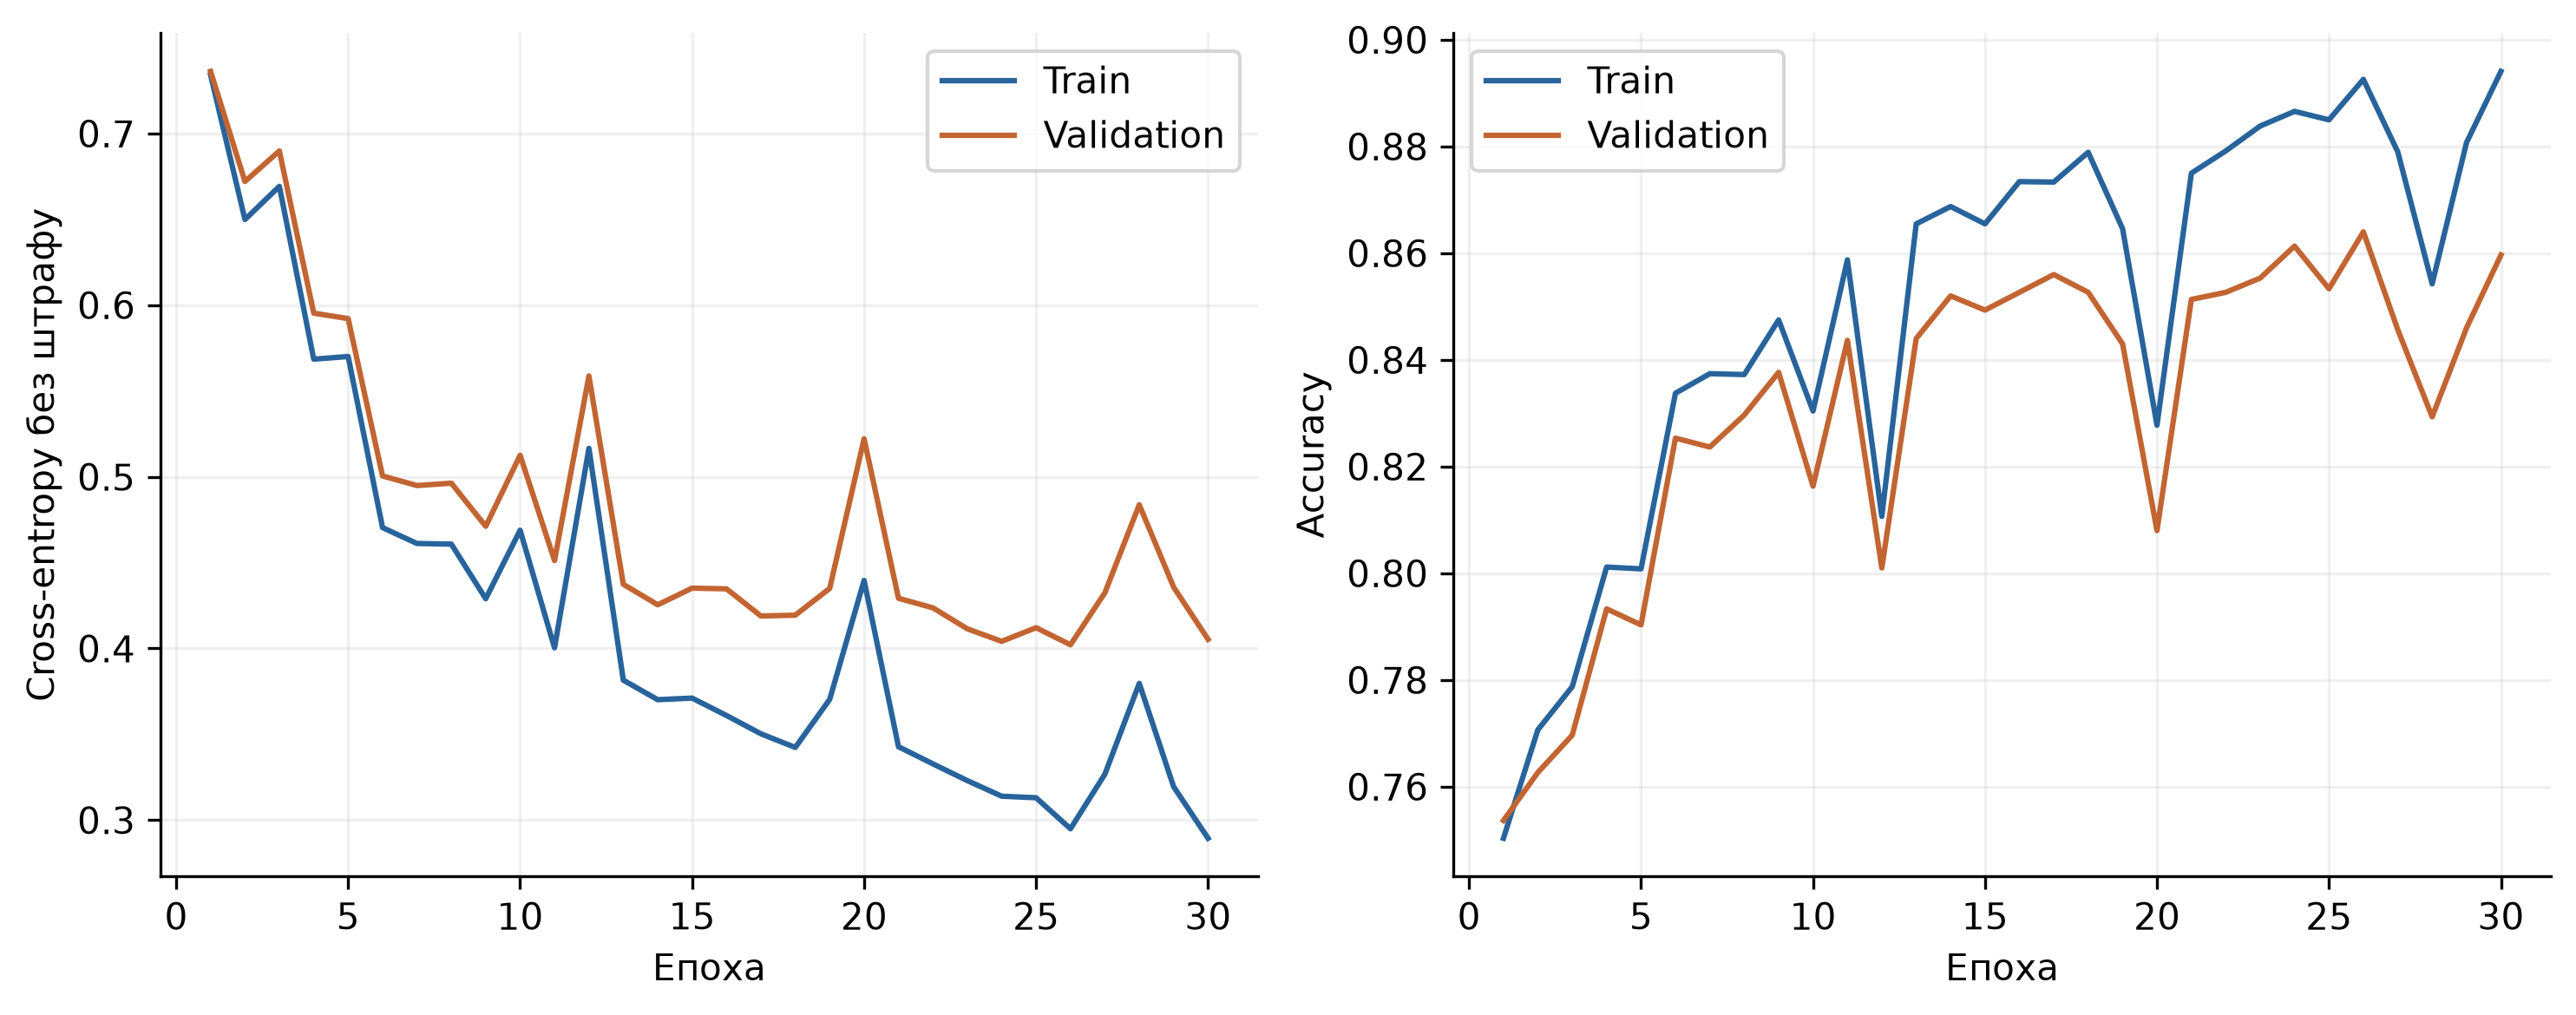

In [12]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'learning_curves.png')))

### Рисунок 2. Розподіли ваг прихованих шарів: Baseline

На рисунку 2 зображено розподіли ваг прихованих шарів: Baseline. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

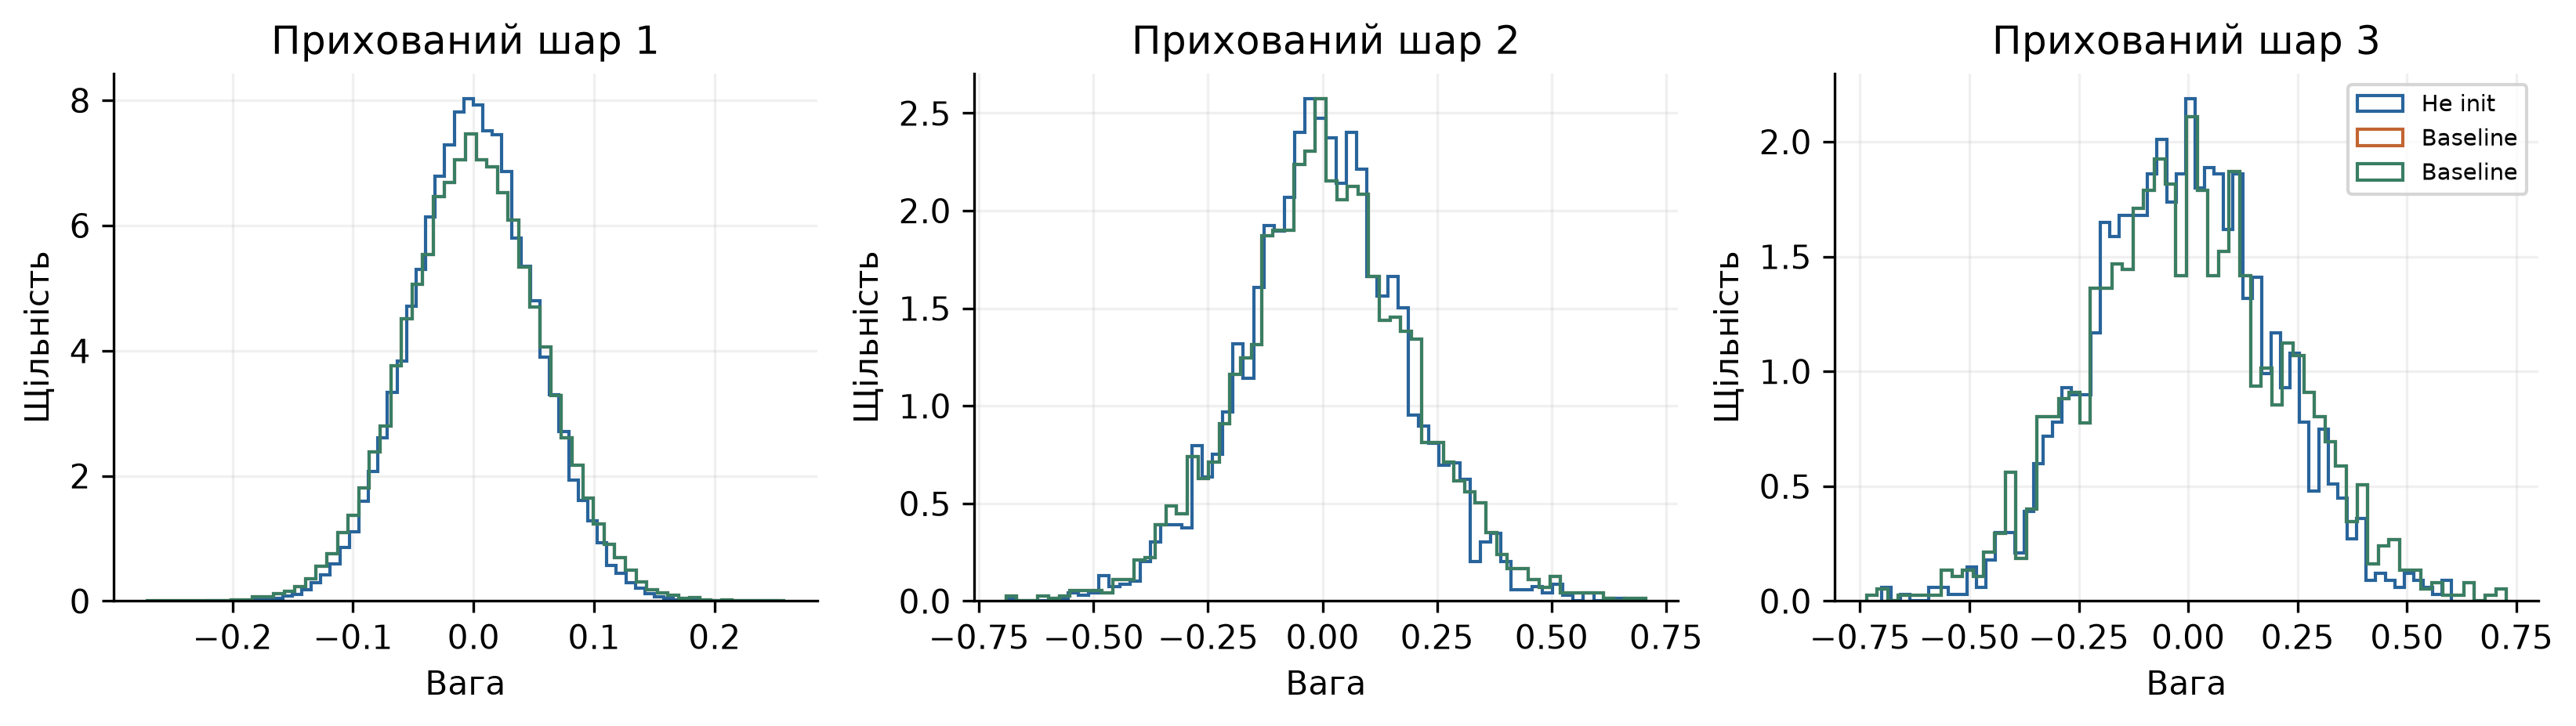

In [13]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_00.png')))

### Рисунок 3. Розподіли ваг прихованих шарів: L1 0.0001

На рисунку 3 зображено розподіли ваг прихованих шарів: L1 0.0001. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

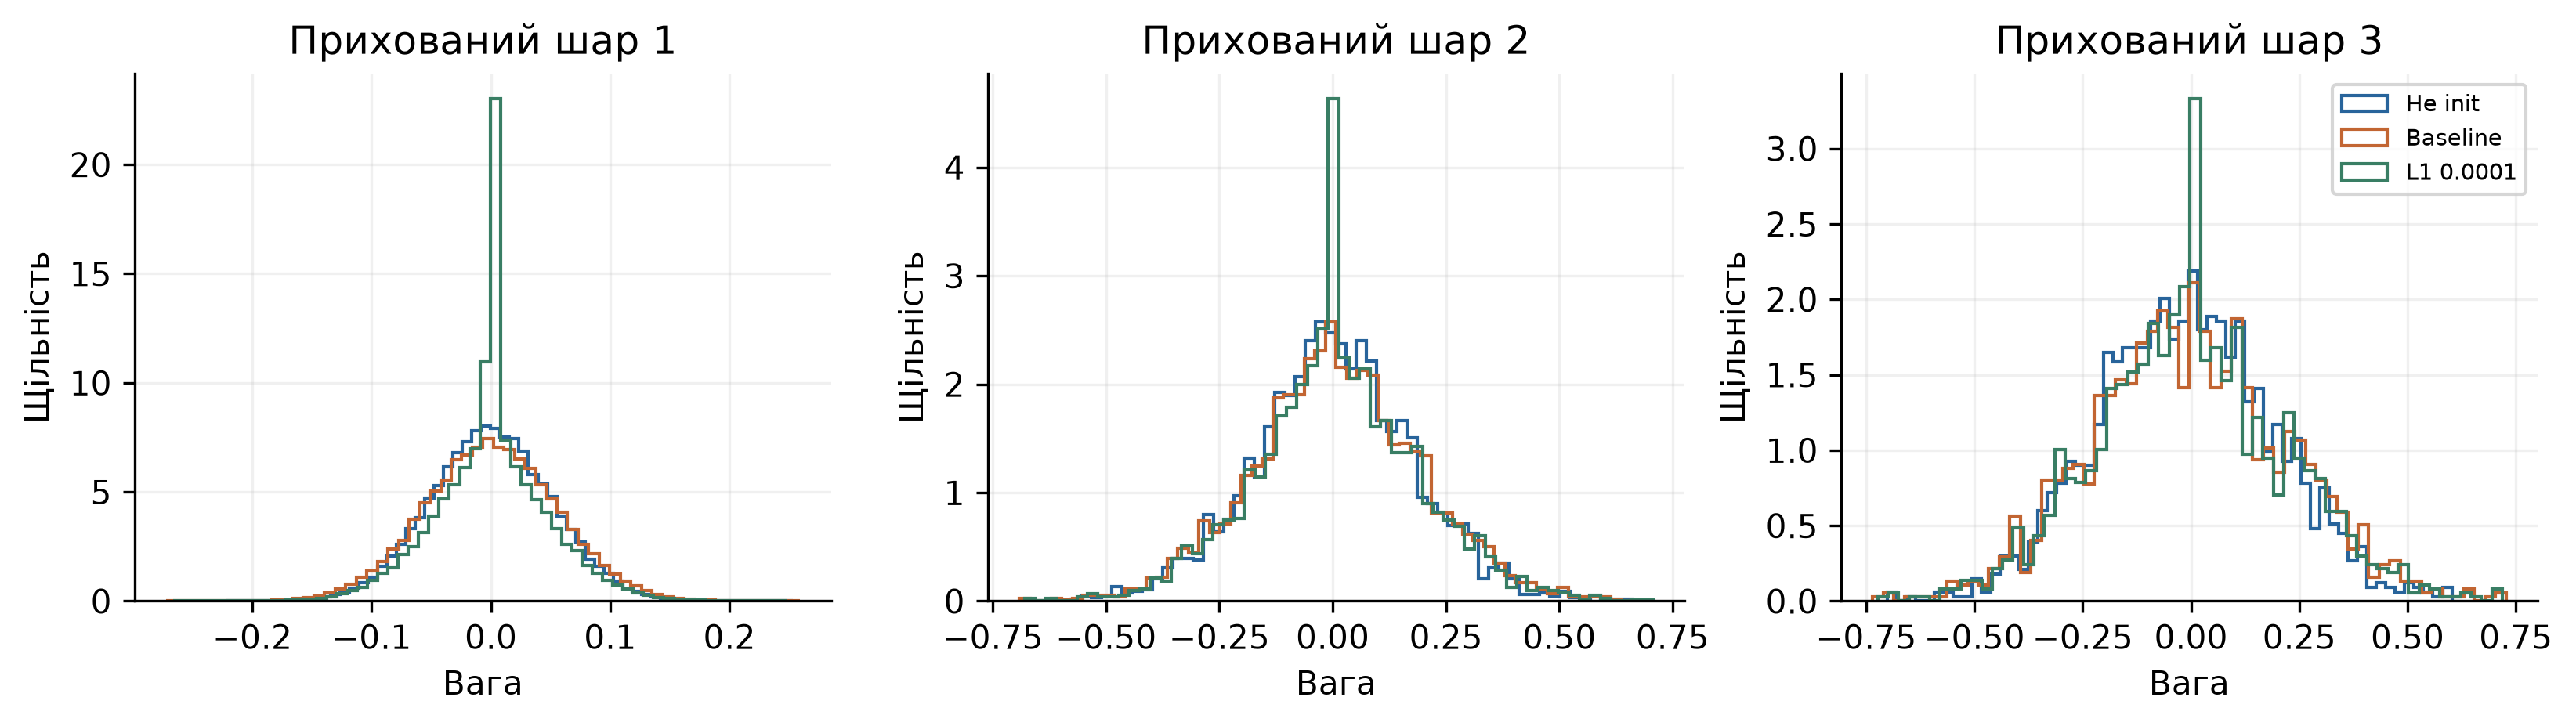

In [14]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_01.png')))

### Рисунок 4. Розподіли ваг прихованих шарів: L1 0.001

На рисунку 4 зображено розподіли ваг прихованих шарів: L1 0.001. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

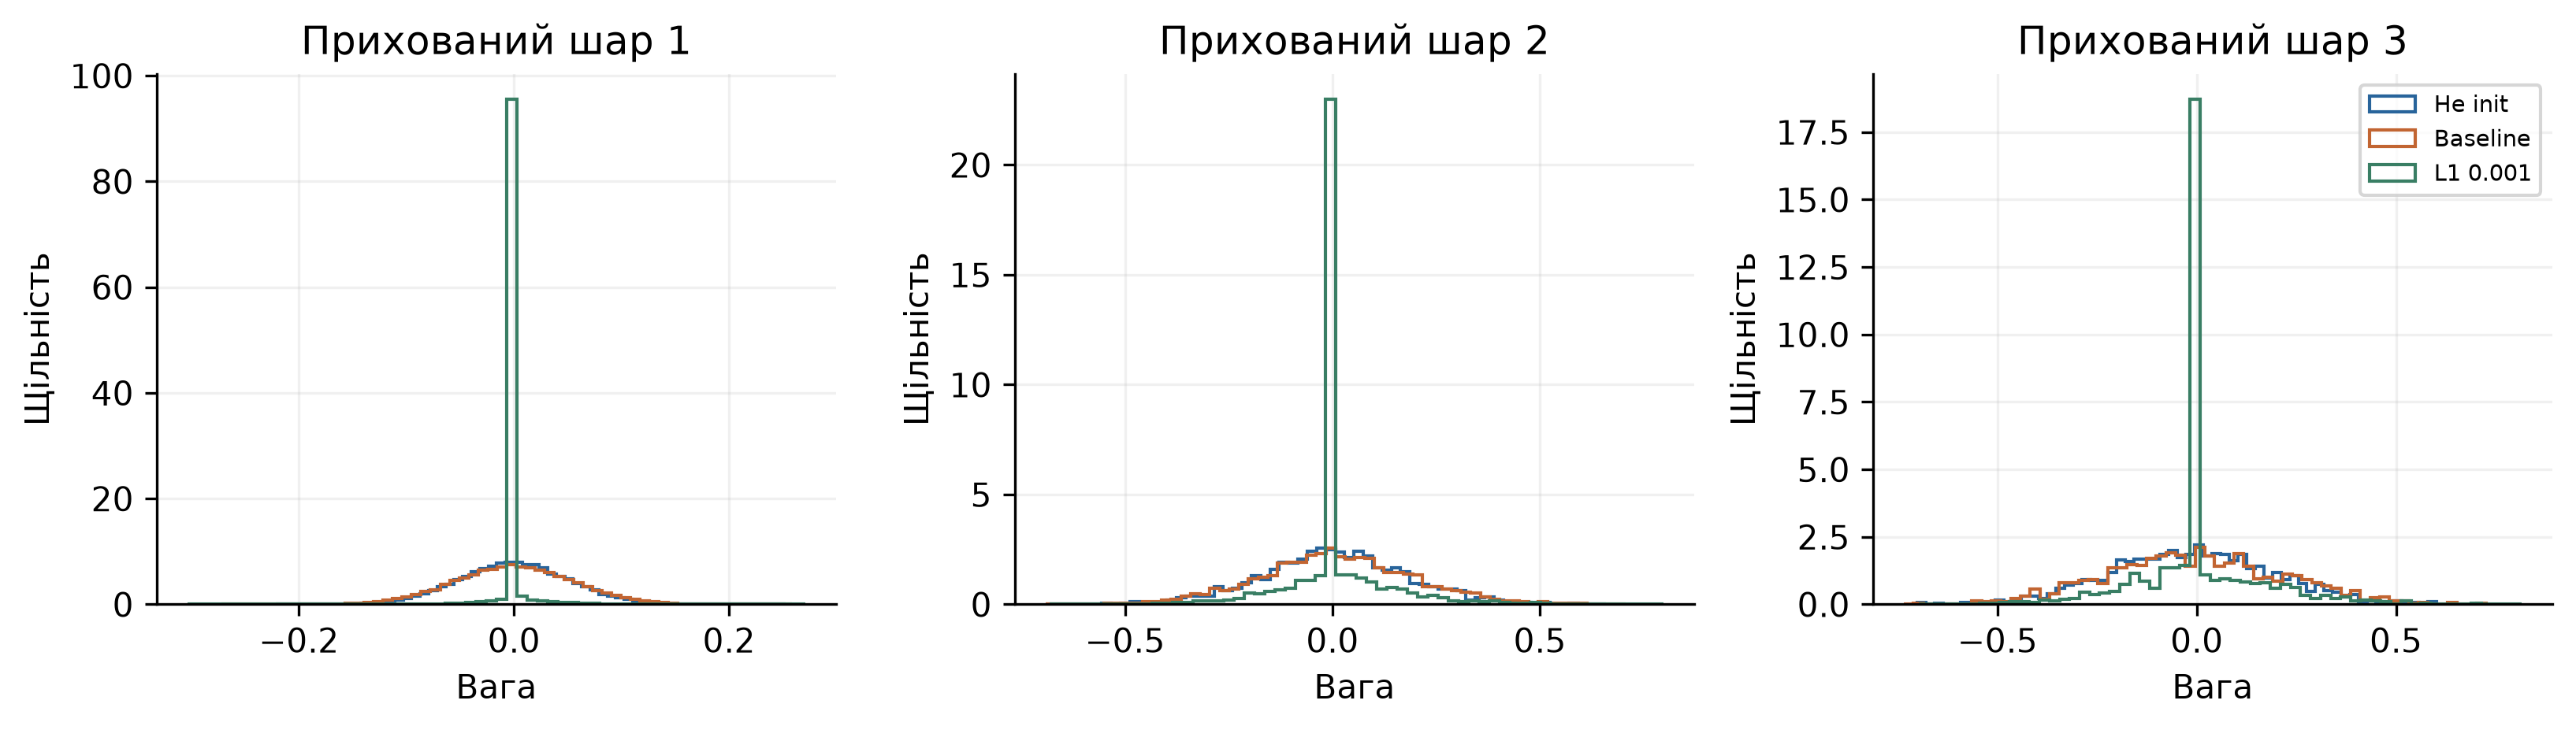

In [15]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_02.png')))

### Рисунок 5. Розподіли ваг прихованих шарів: L2 0.0001

На рисунку 5 зображено розподіли ваг прихованих шарів: L2 0.0001. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

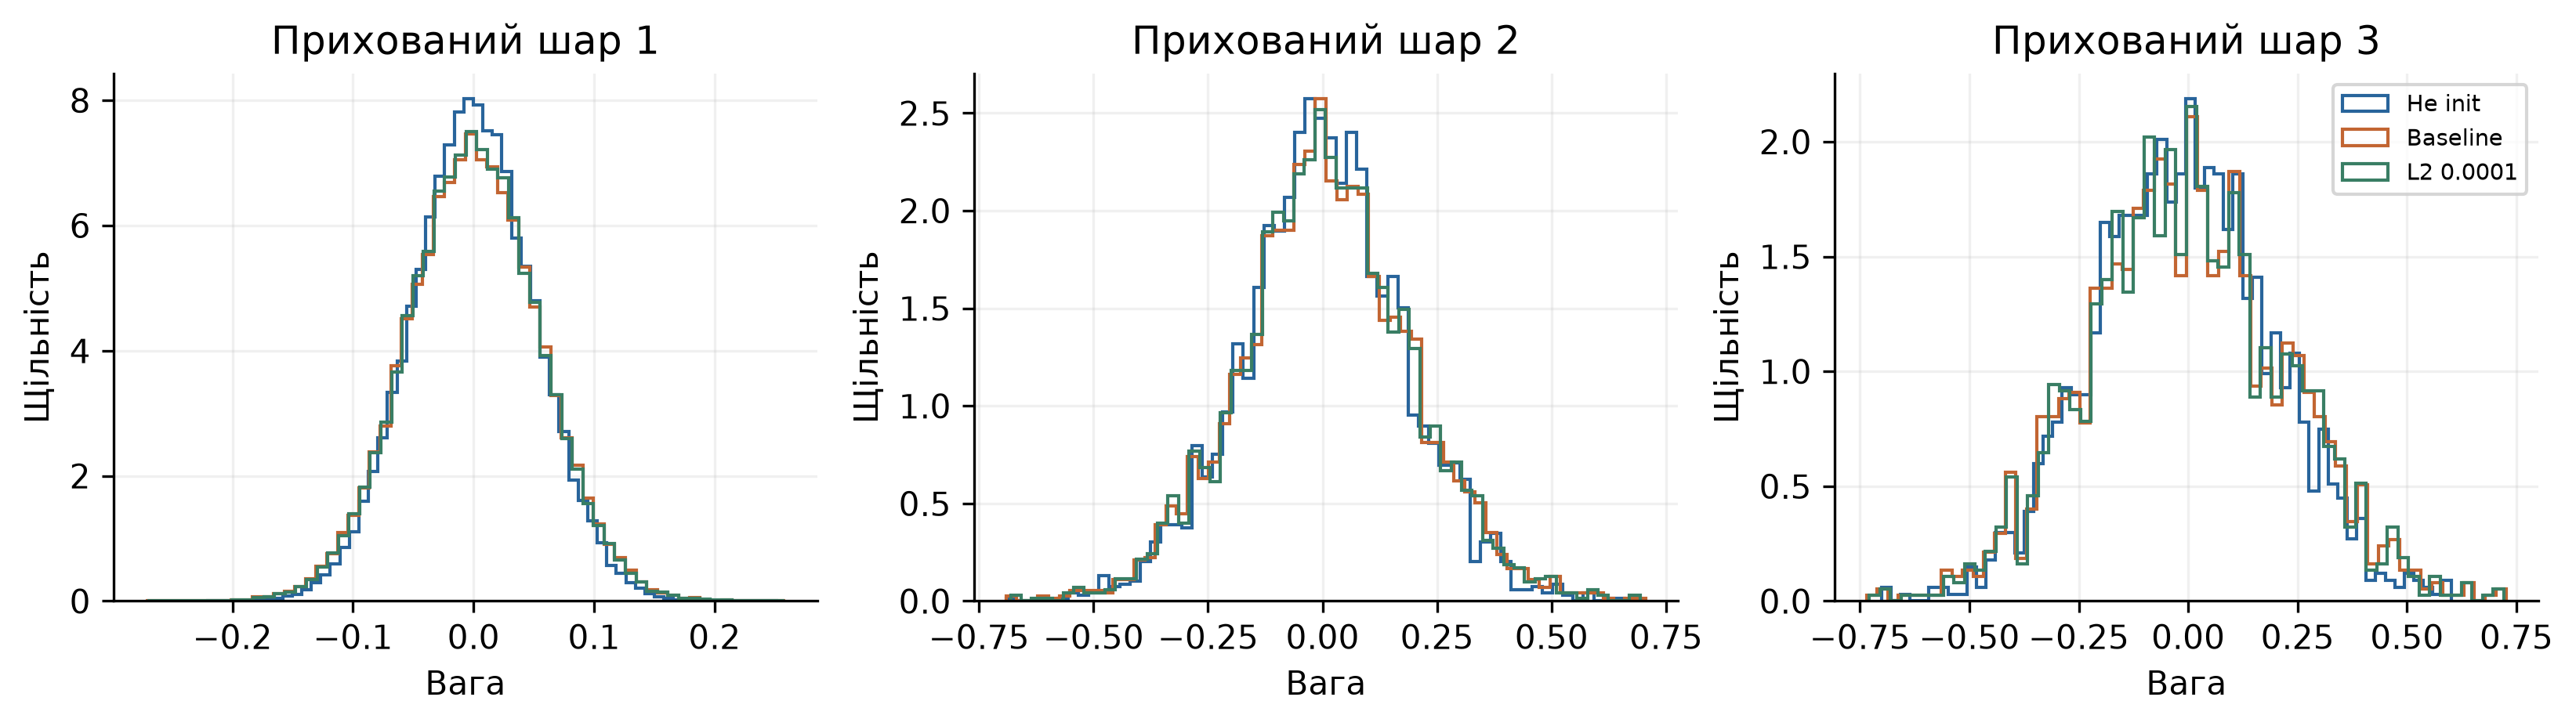

In [16]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_03.png')))

### Рисунок 6. Розподіли ваг прихованих шарів: L2 0.01

На рисунку 6 зображено розподіли ваг прихованих шарів: L2 0.01. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

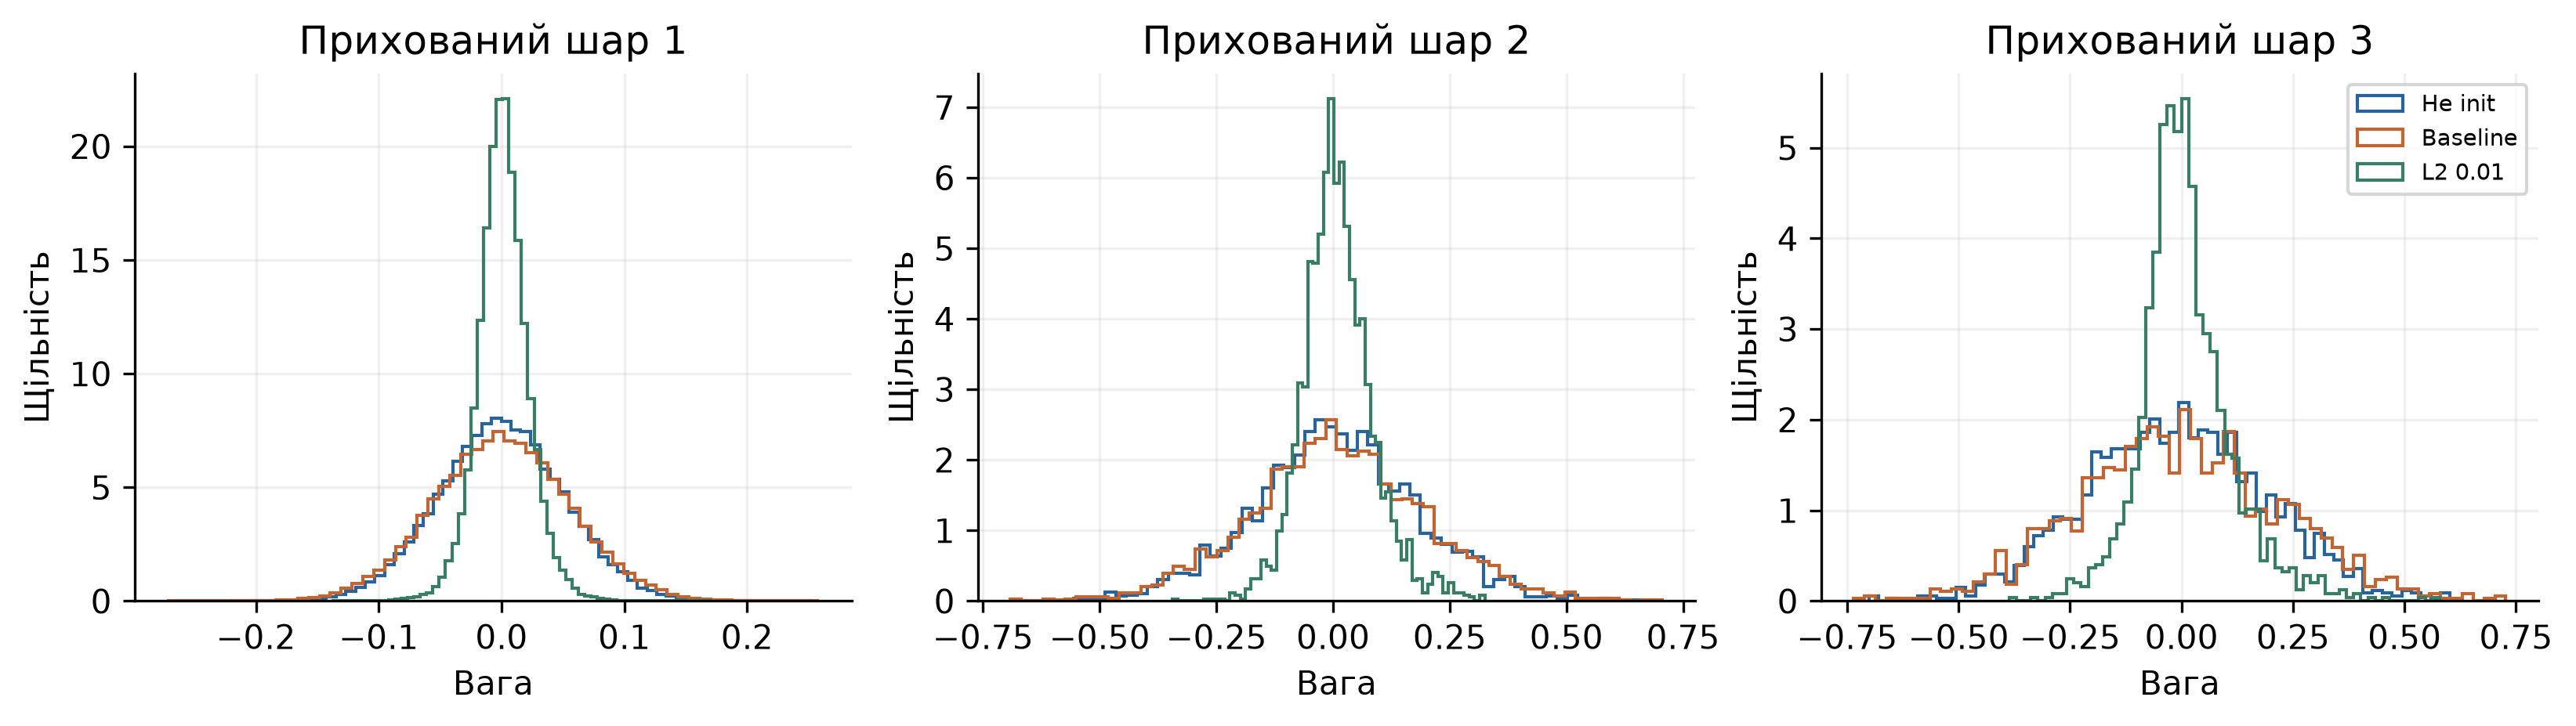

In [17]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_04.png')))

### Рисунок 7. Розподіли ваг прихованих шарів: Dropout 0.1

На рисунку 7 зображено розподіли ваг прихованих шарів: Dropout 0.1. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

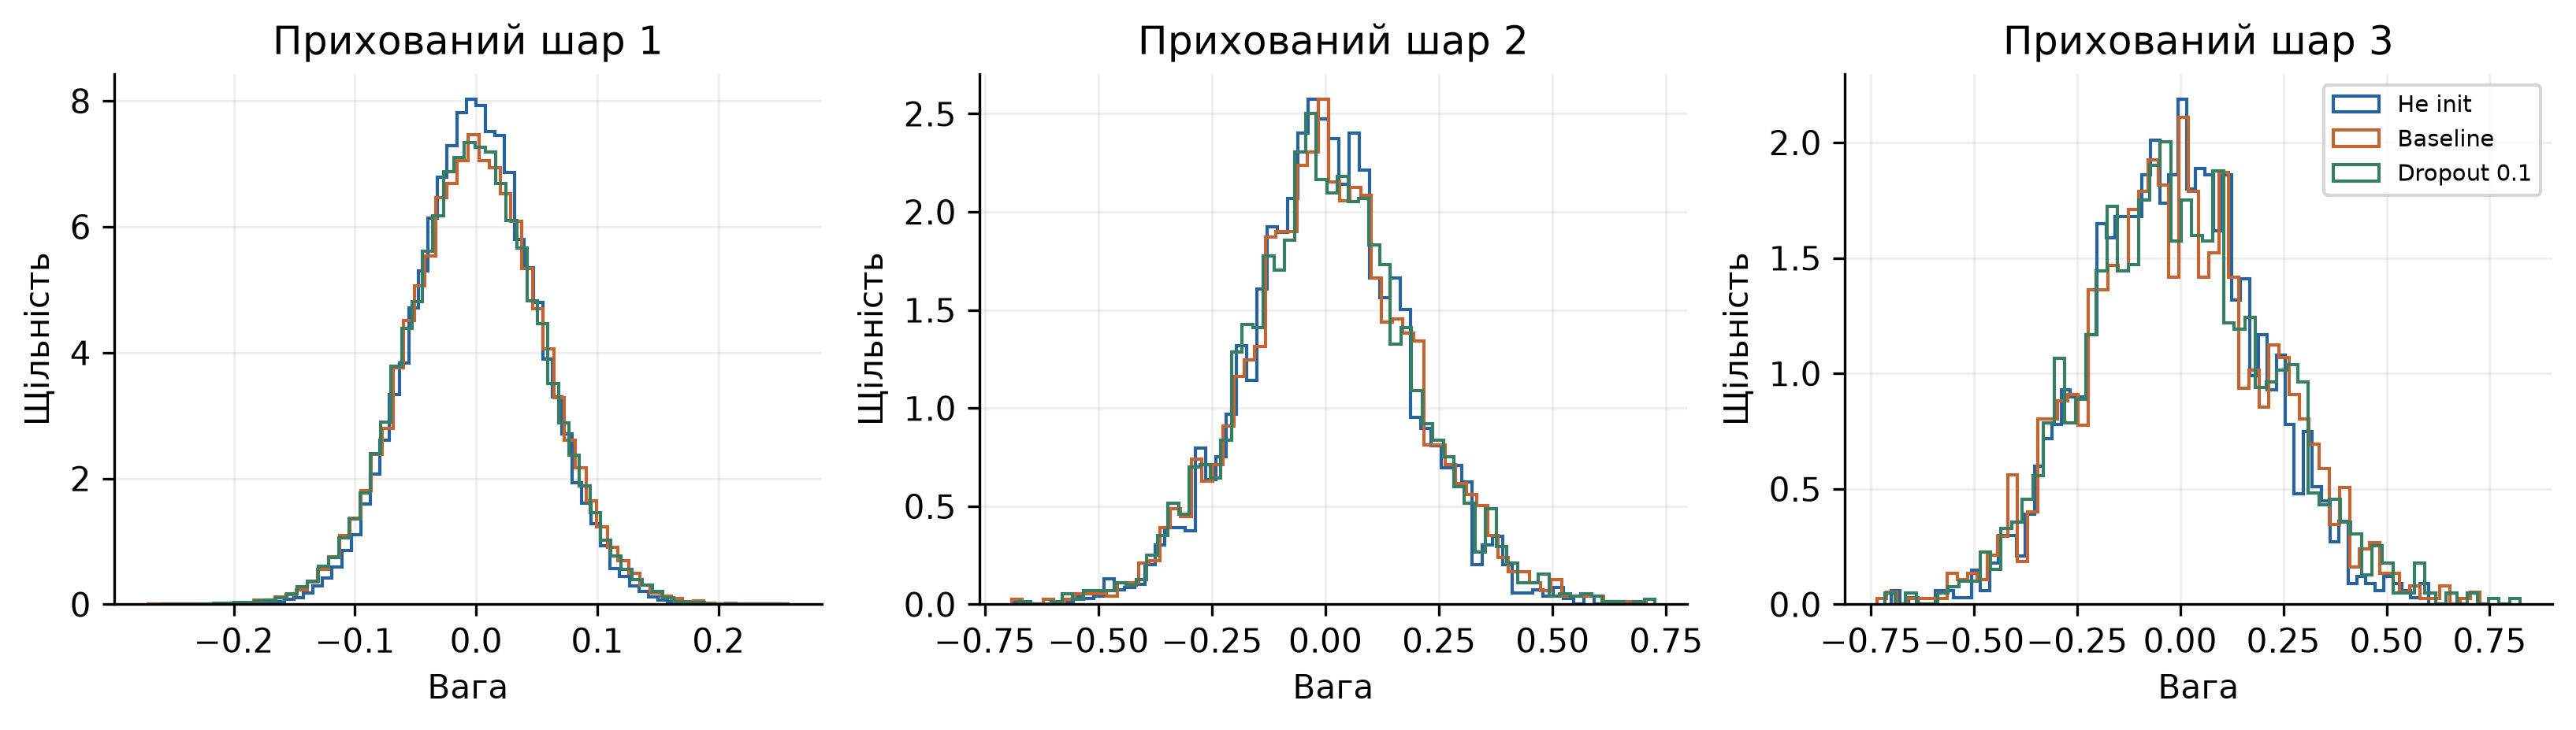

In [18]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_05.png')))

### Рисунок 8. Розподіли ваг прихованих шарів: Dropout 0.2

На рисунку 8 зображено розподіли ваг прихованих шарів: Dropout 0.2. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

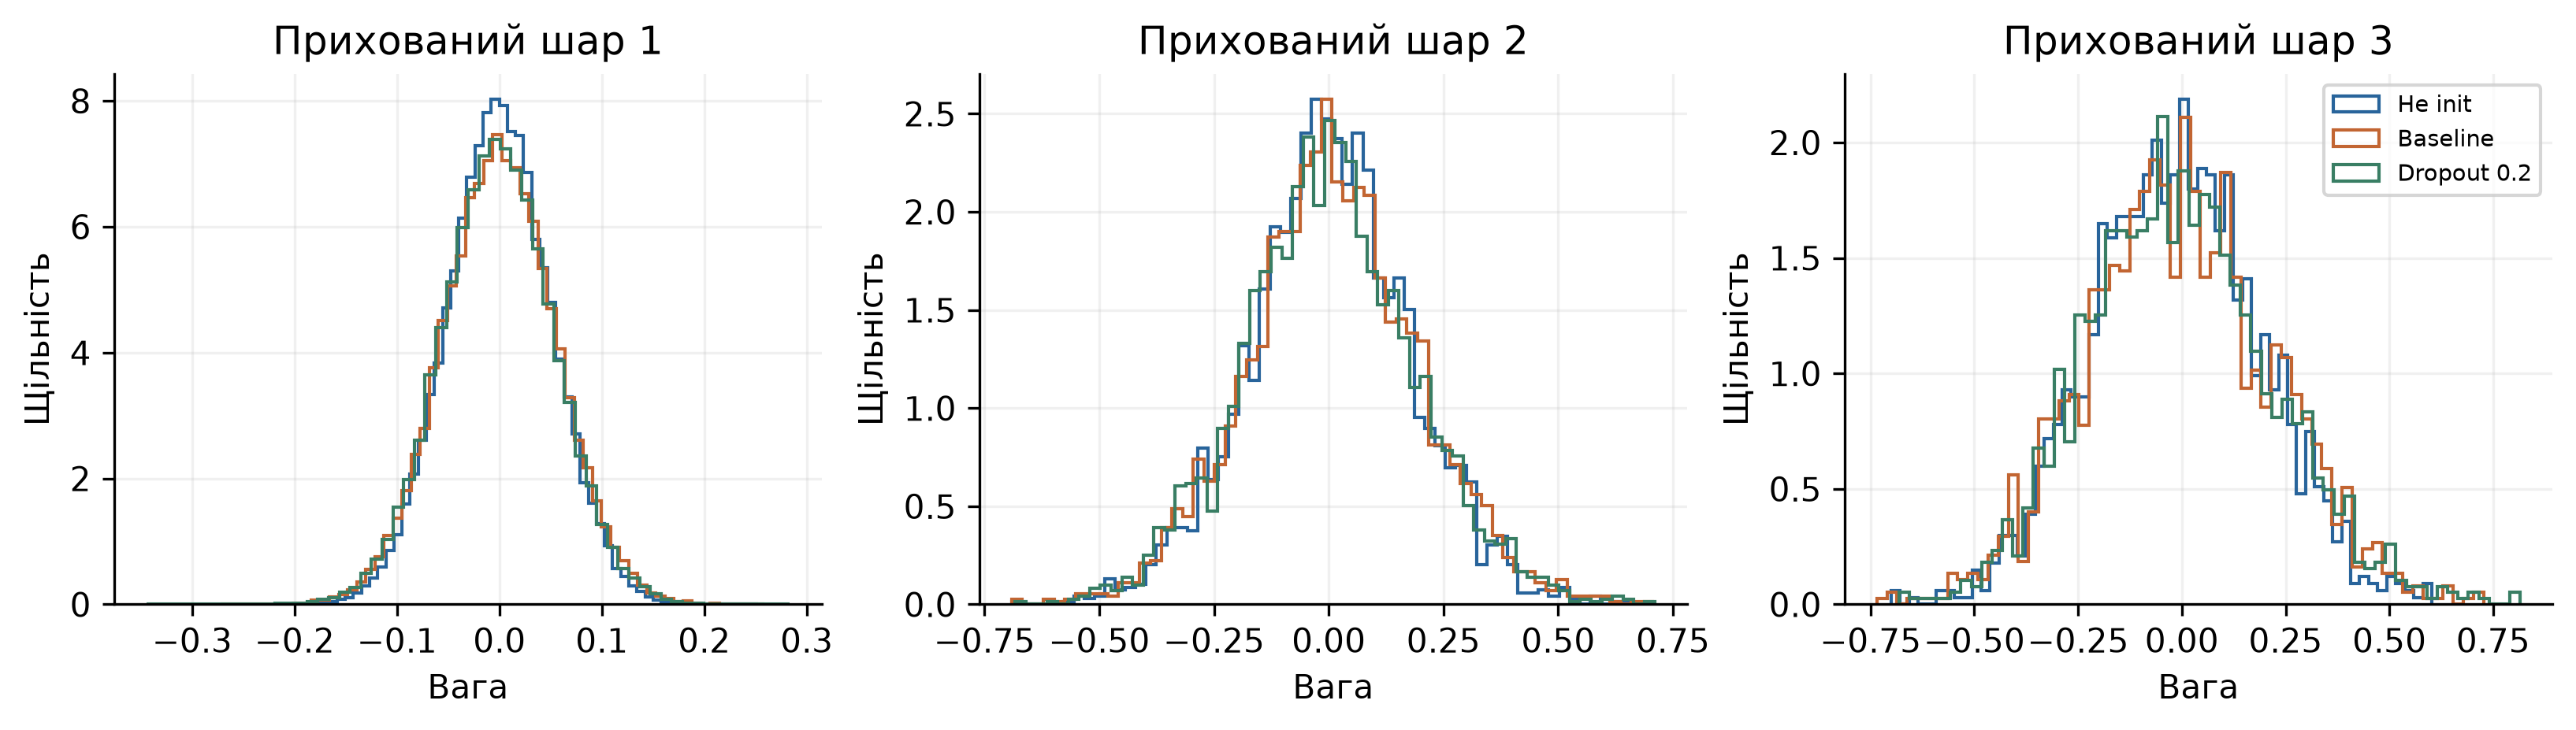

In [19]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_06.png')))

### Рисунок 9. Розподіли ваг прихованих шарів: Dropout 0.3

На рисунку 9 зображено розподіли ваг прихованих шарів: Dropout 0.3. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

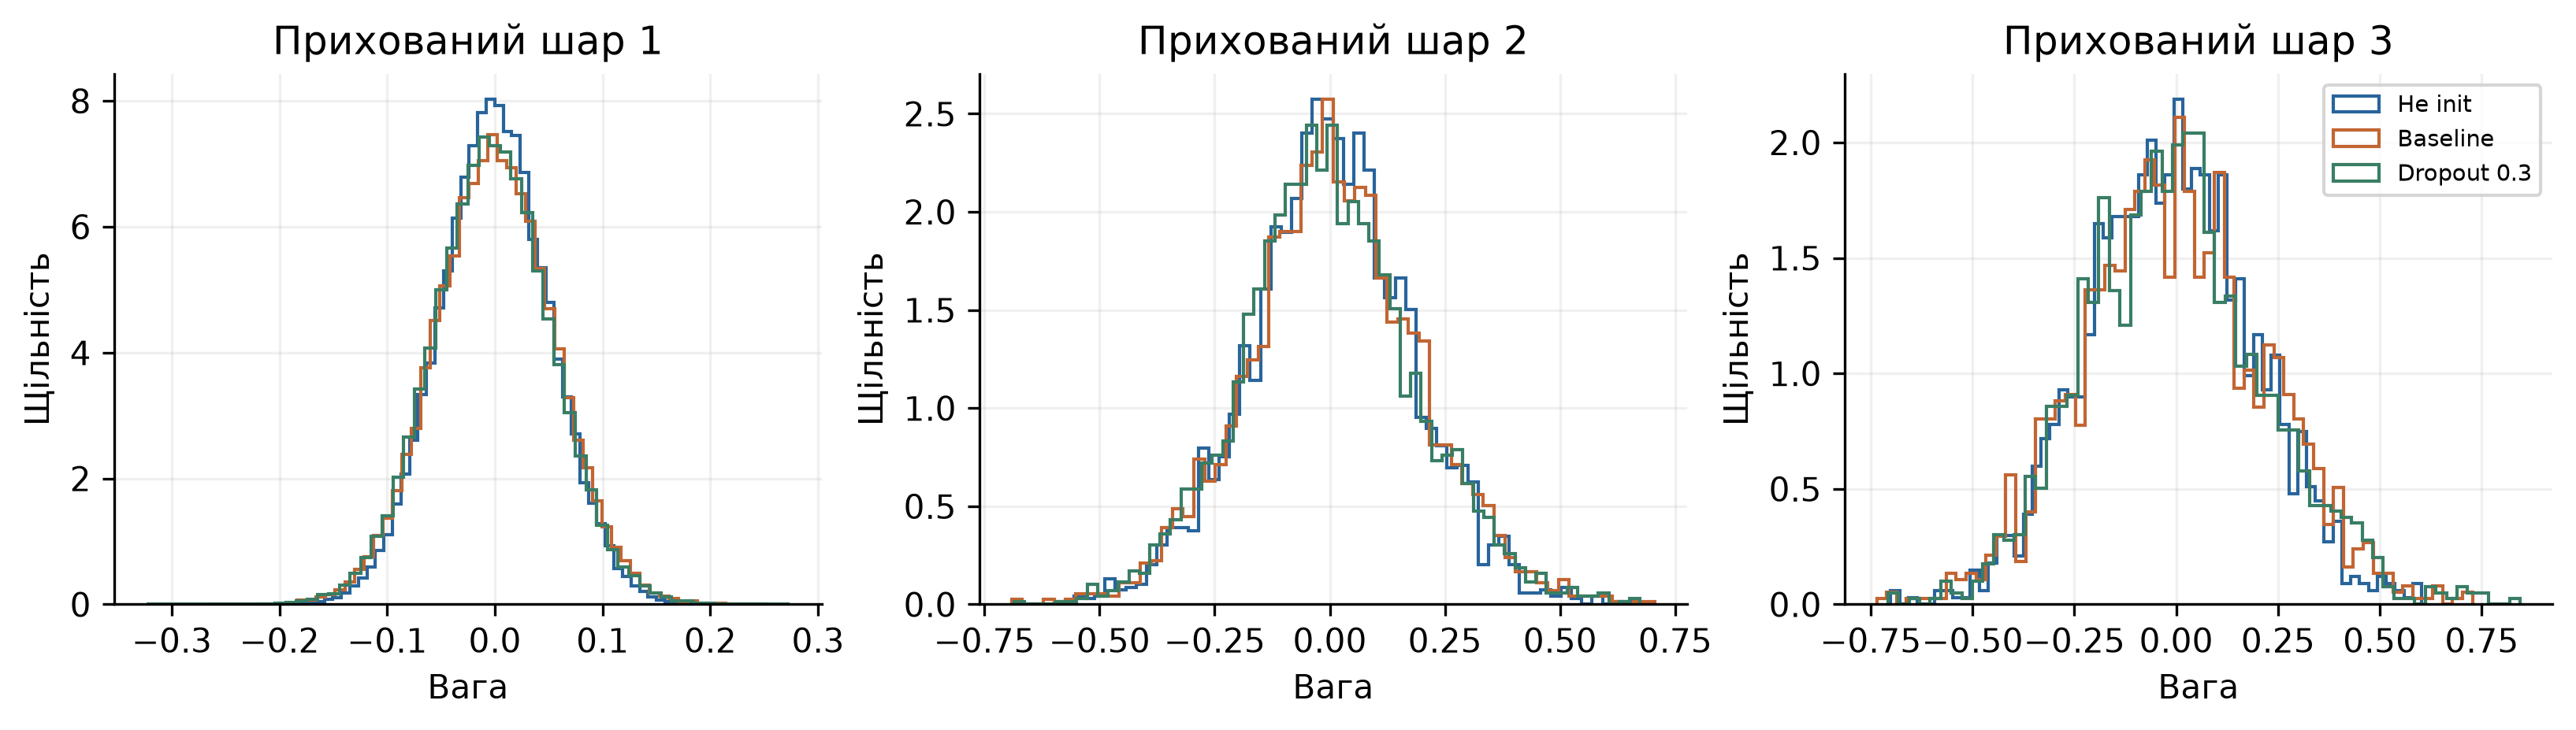

In [20]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_07.png')))

### Рисунок 10. Розподіли ваг прихованих шарів: Dropout 0.5

На рисунку 10 зображено розподіли ваг прихованих шарів: Dropout 0.5. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

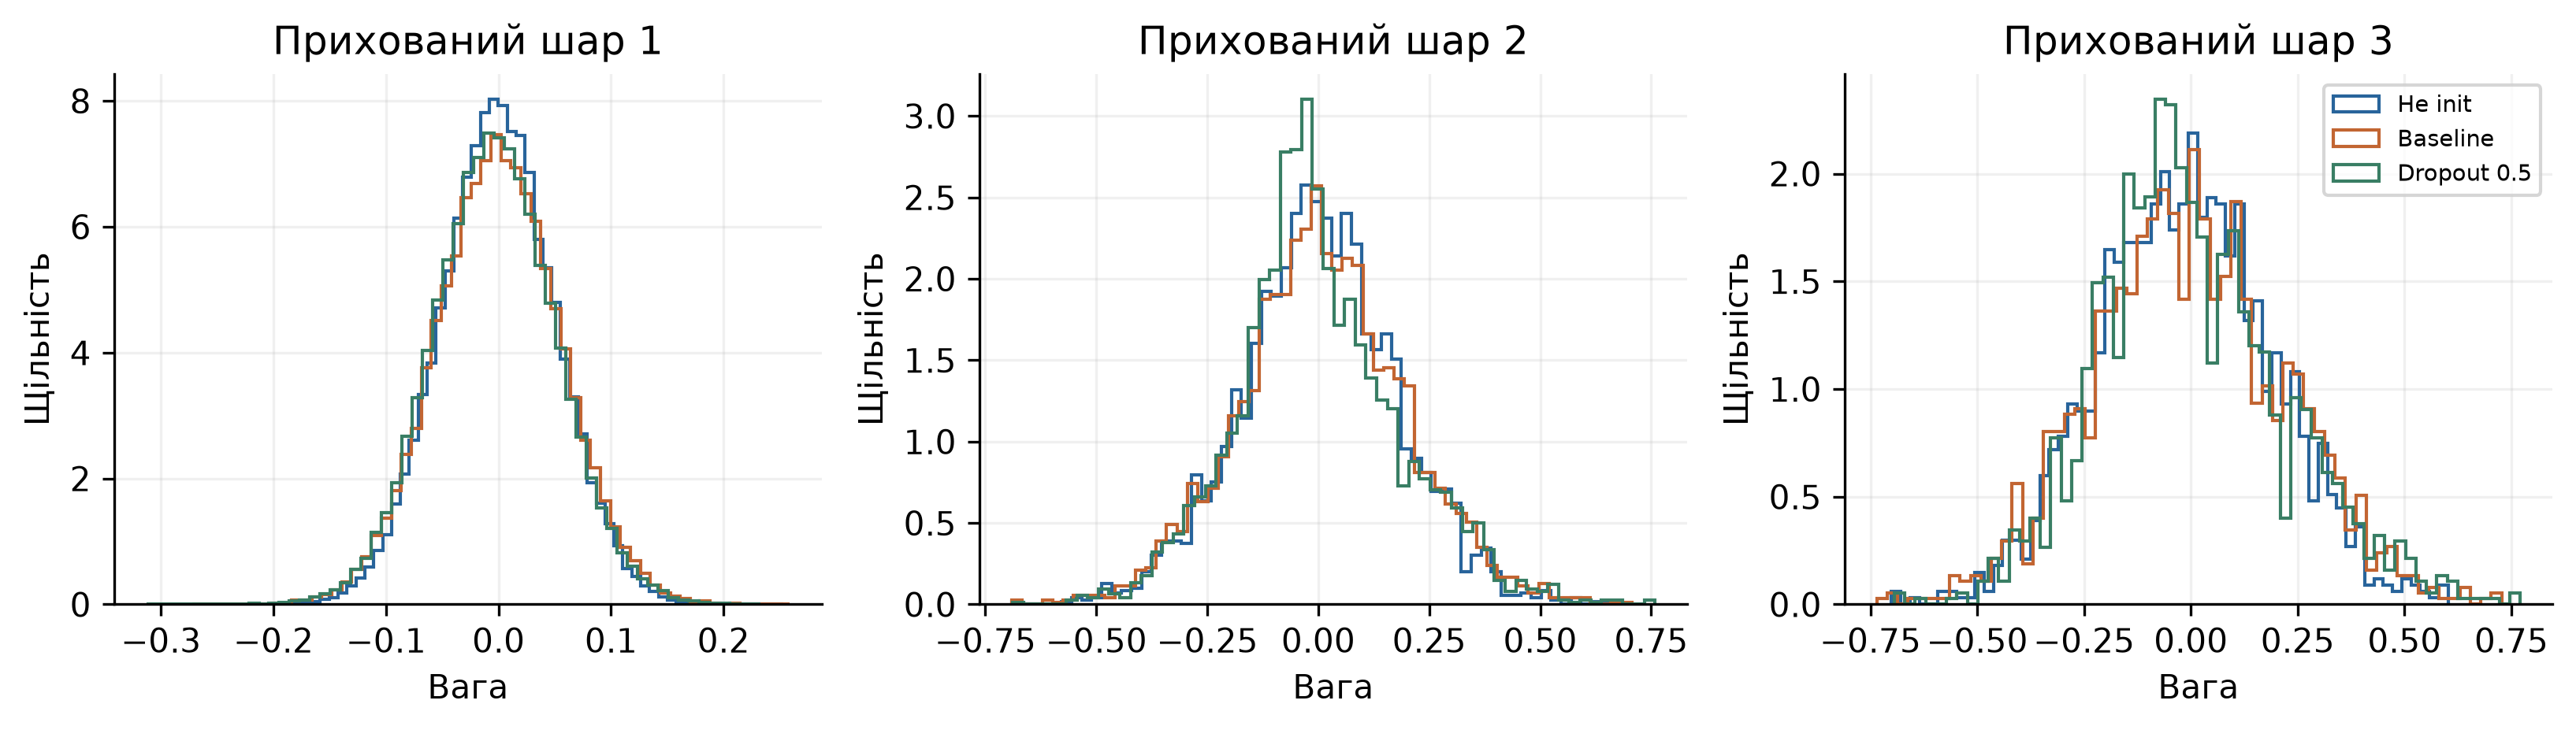

In [21]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_08.png')))

### Рисунок 11. Розподіли ваг прихованих шарів: Weight clip 1

На рисунку 11 зображено розподіли ваг прихованих шарів: Weight clip 1. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

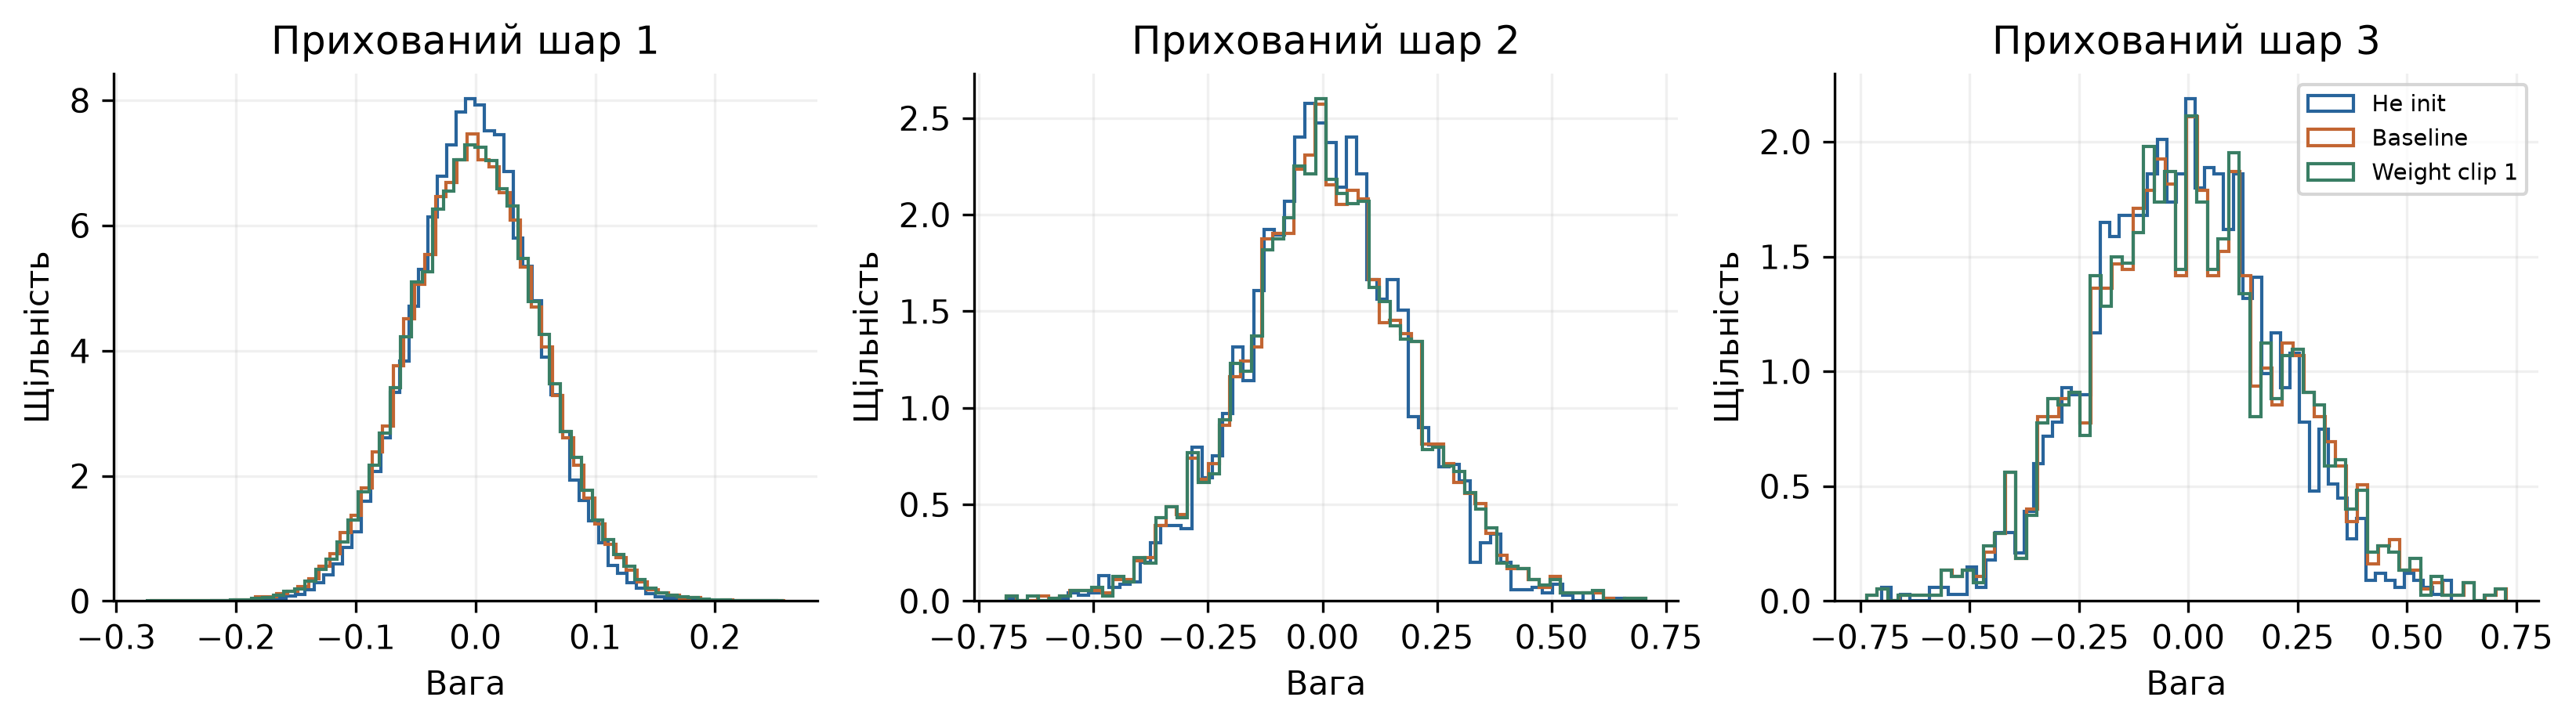

In [22]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_09.png')))

### Рисунок 12. Розподіли ваг прихованих шарів: Gradient clip 0.1

На рисунку 12 зображено розподіли ваг прихованих шарів: Gradient clip 0.1. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

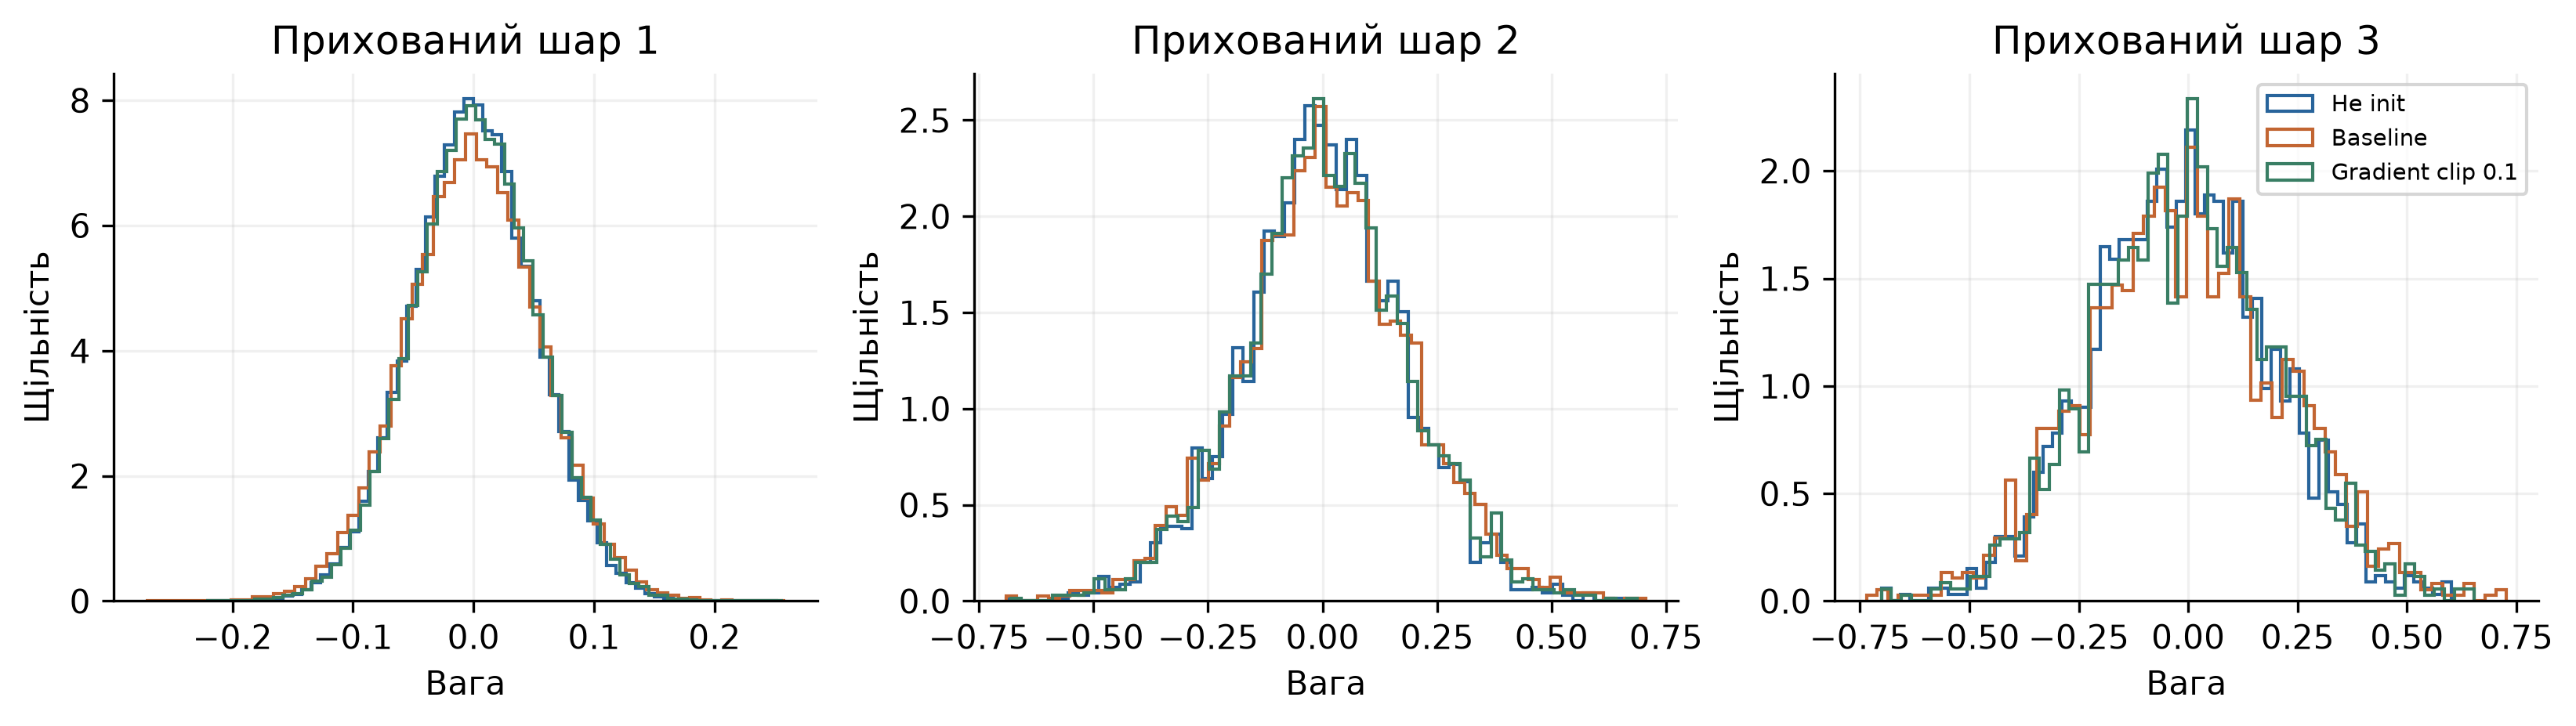

In [23]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_10.png')))

### Рисунок 13. Розподіли ваг прихованих шарів: Gradient clip 1

На рисунку 13 зображено розподіли ваг прихованих шарів: Gradient clip 1. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

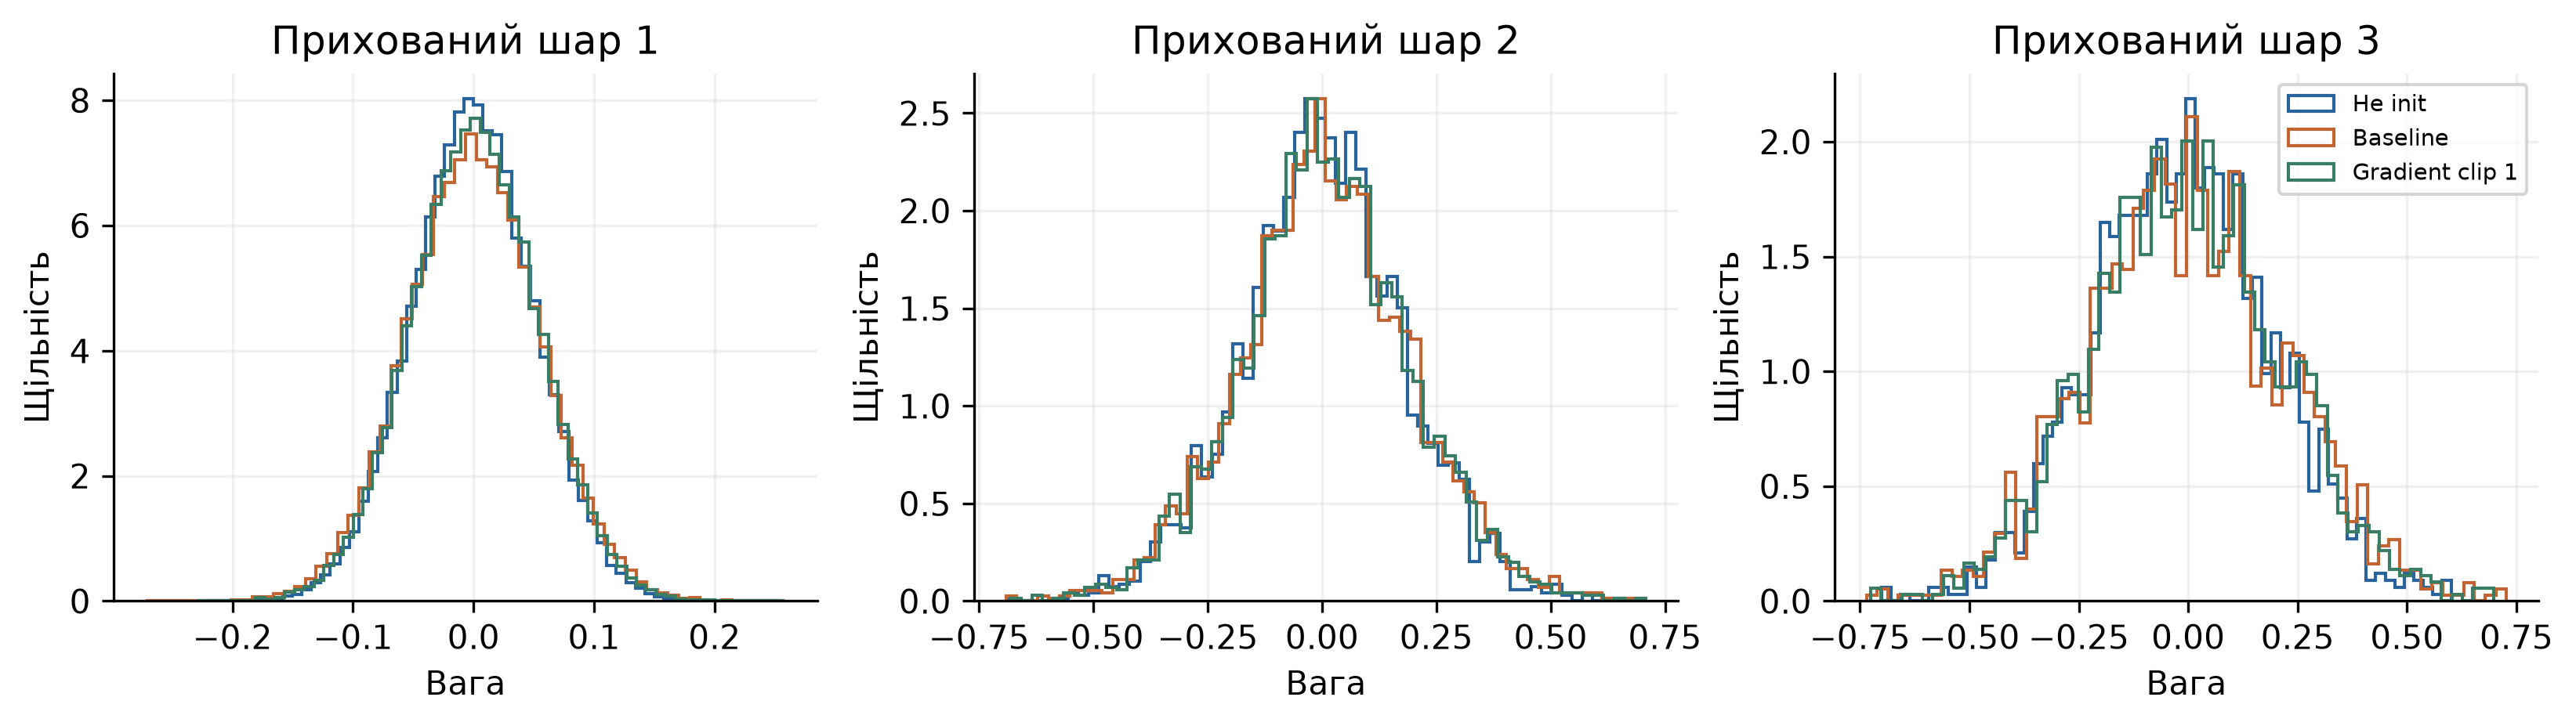

In [24]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_11.png')))

### Рисунок 14. Розподіли ваг прихованих шарів: L2 + Dropout 0.2

На рисунку 14 зображено розподіли ваг прихованих шарів: L2 + Dropout 0.2. Порівнюються початкова He-ініціалізація, кінцевий Baseline та відповідний метод регуляризації. Для всіх трьох шарів збережено однакове визначення ваг.

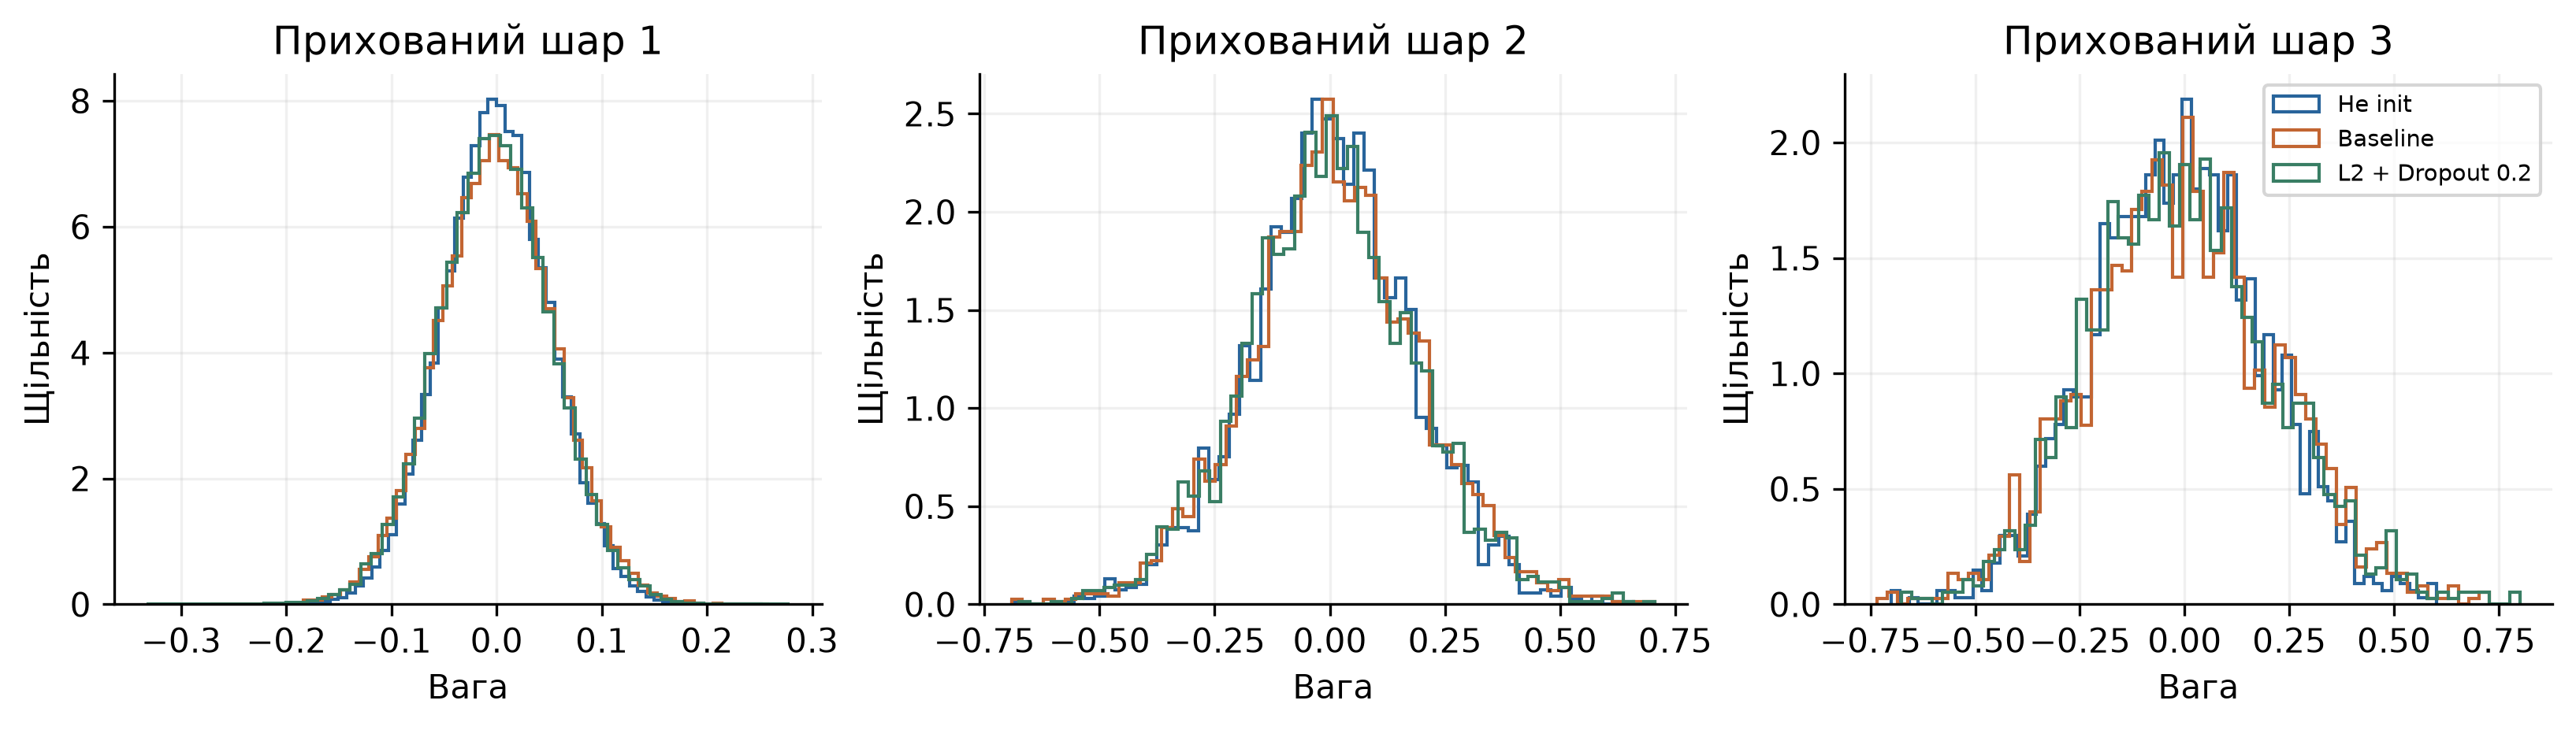

In [25]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'weights_12.png')))

### Рисунок 15. Зв’язок частки мертвих нейронів і Validation accuracy

На рисунку 15 зображено зв’язок частки мертвих нейронів і Validation accuracy. Окрема точка - один експеримент. Однакова частка мертвих нейронів може відповідати різній точності; лише цей показник не пояснює якість моделі.

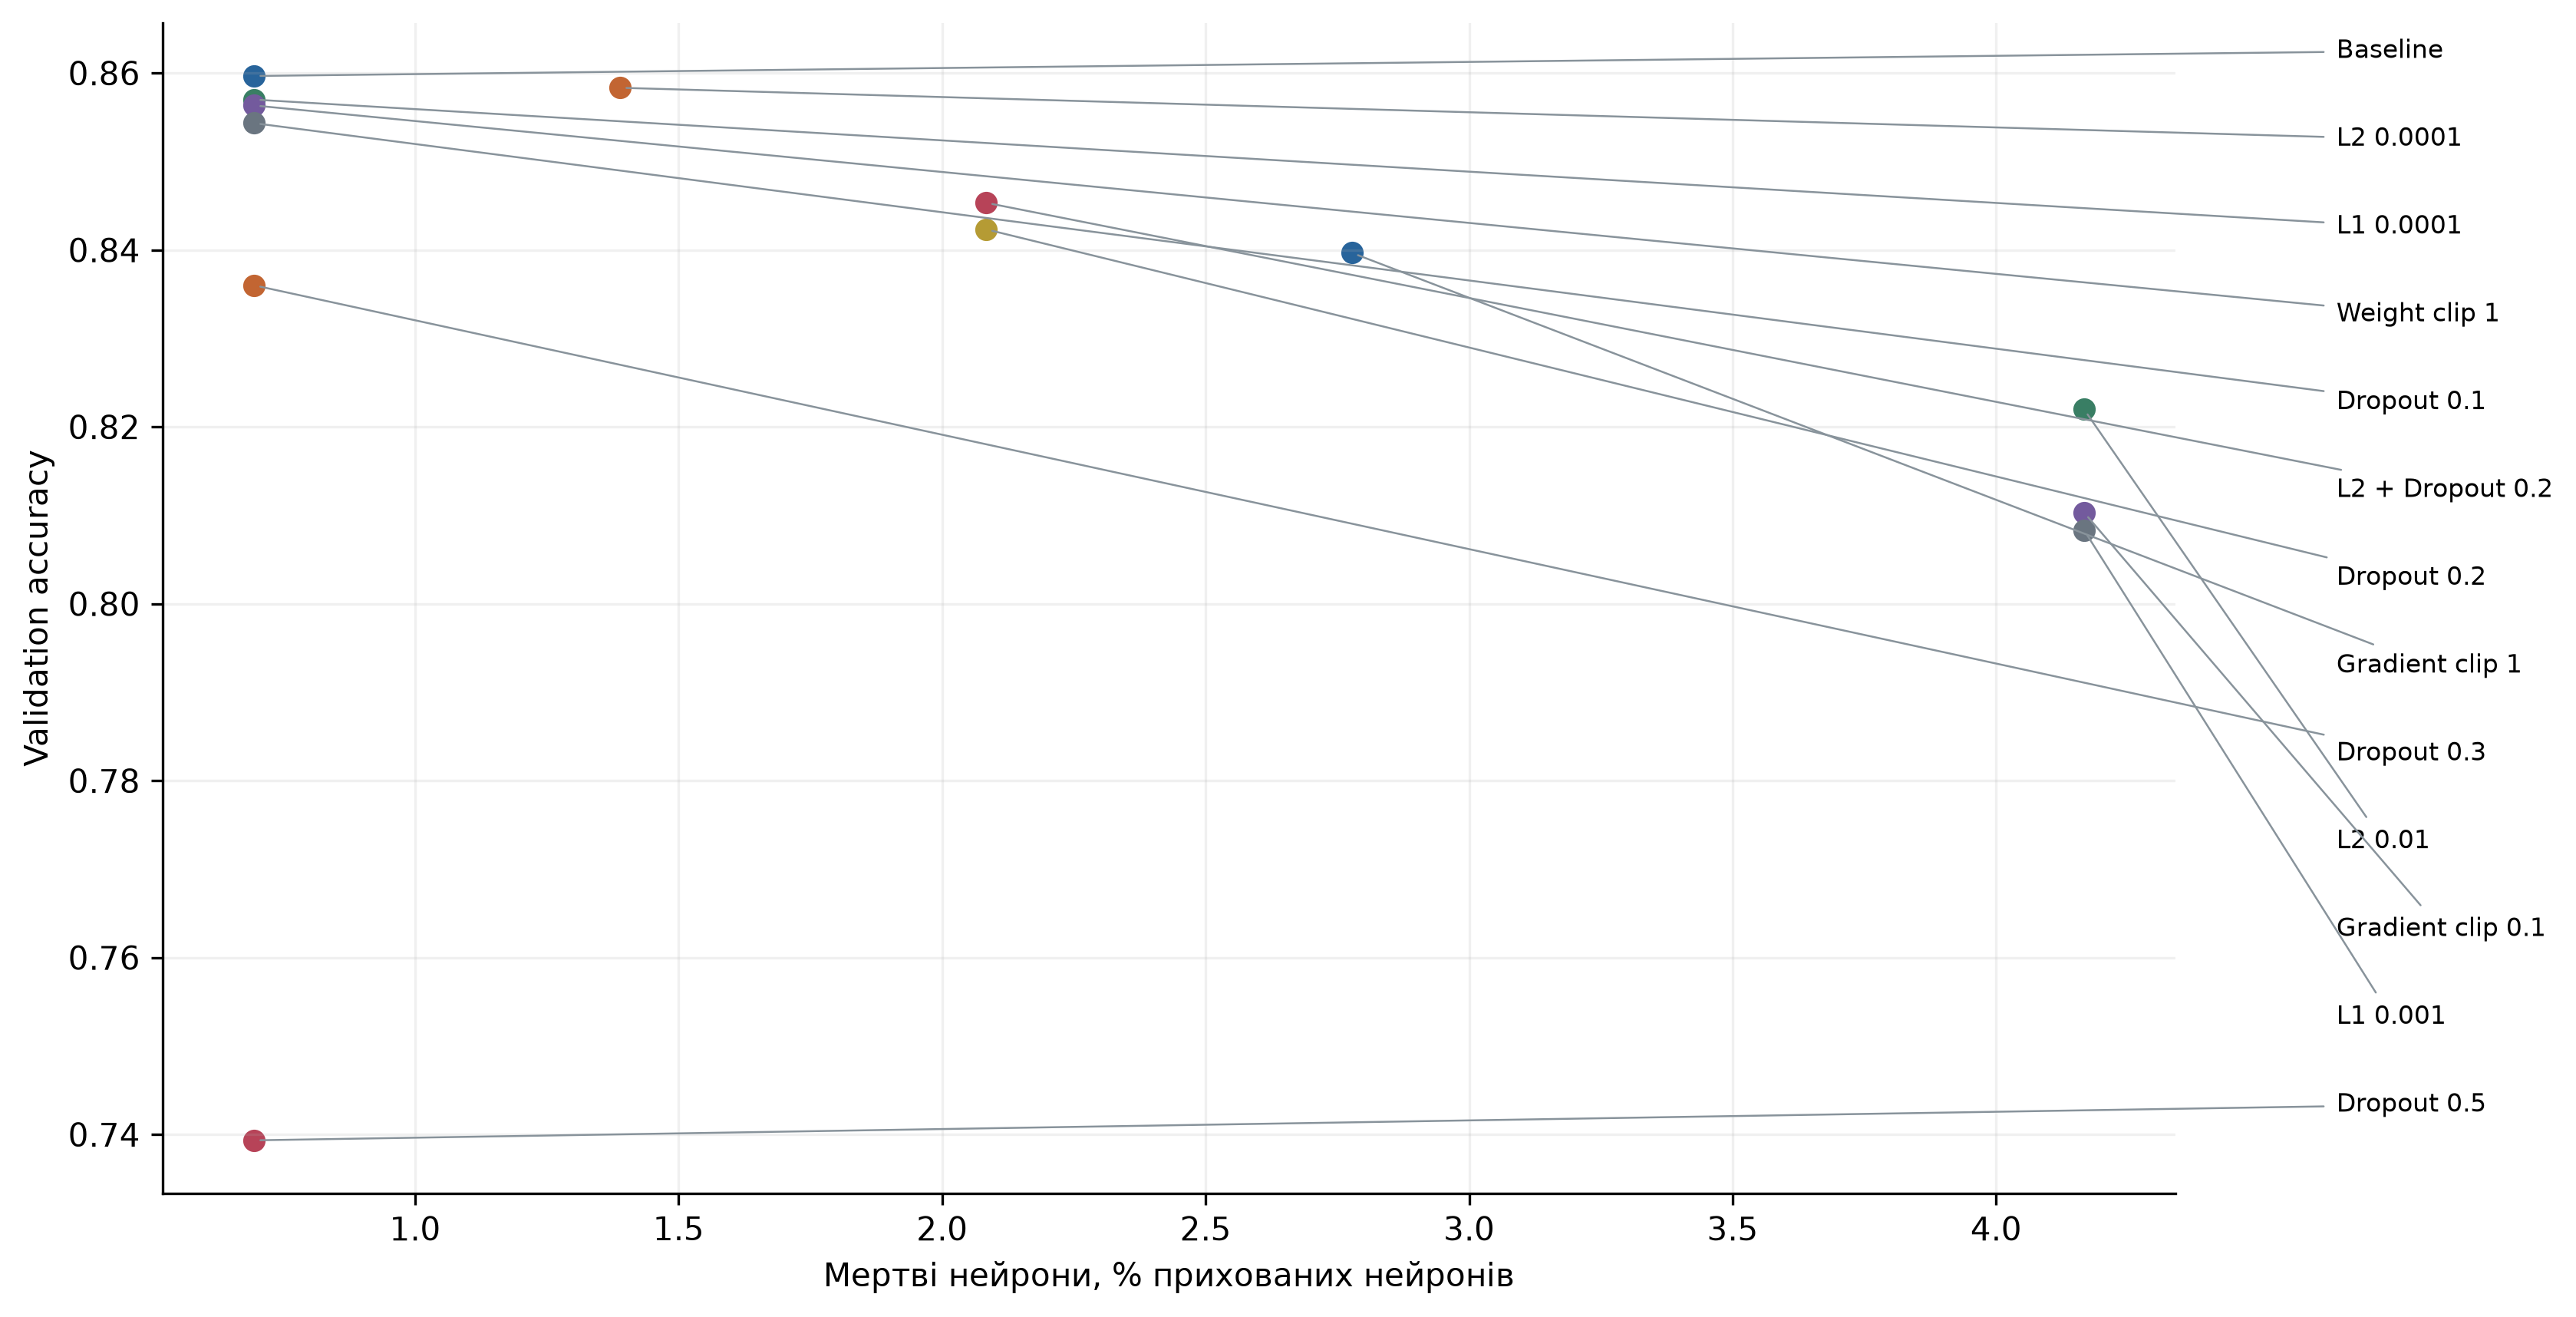

In [26]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'dead_vs_accuracy.png')))

### Рисунок 16. Матриця плутанини вибраної MLP на офіційному Test

На рисунку 16 зображено матриця плутанини вибраної MLP на офіційному Test. Коди 0-9 відповідають стандартним категоріям Fashion-MNIST; їх розшифрування наведено в описі даних.

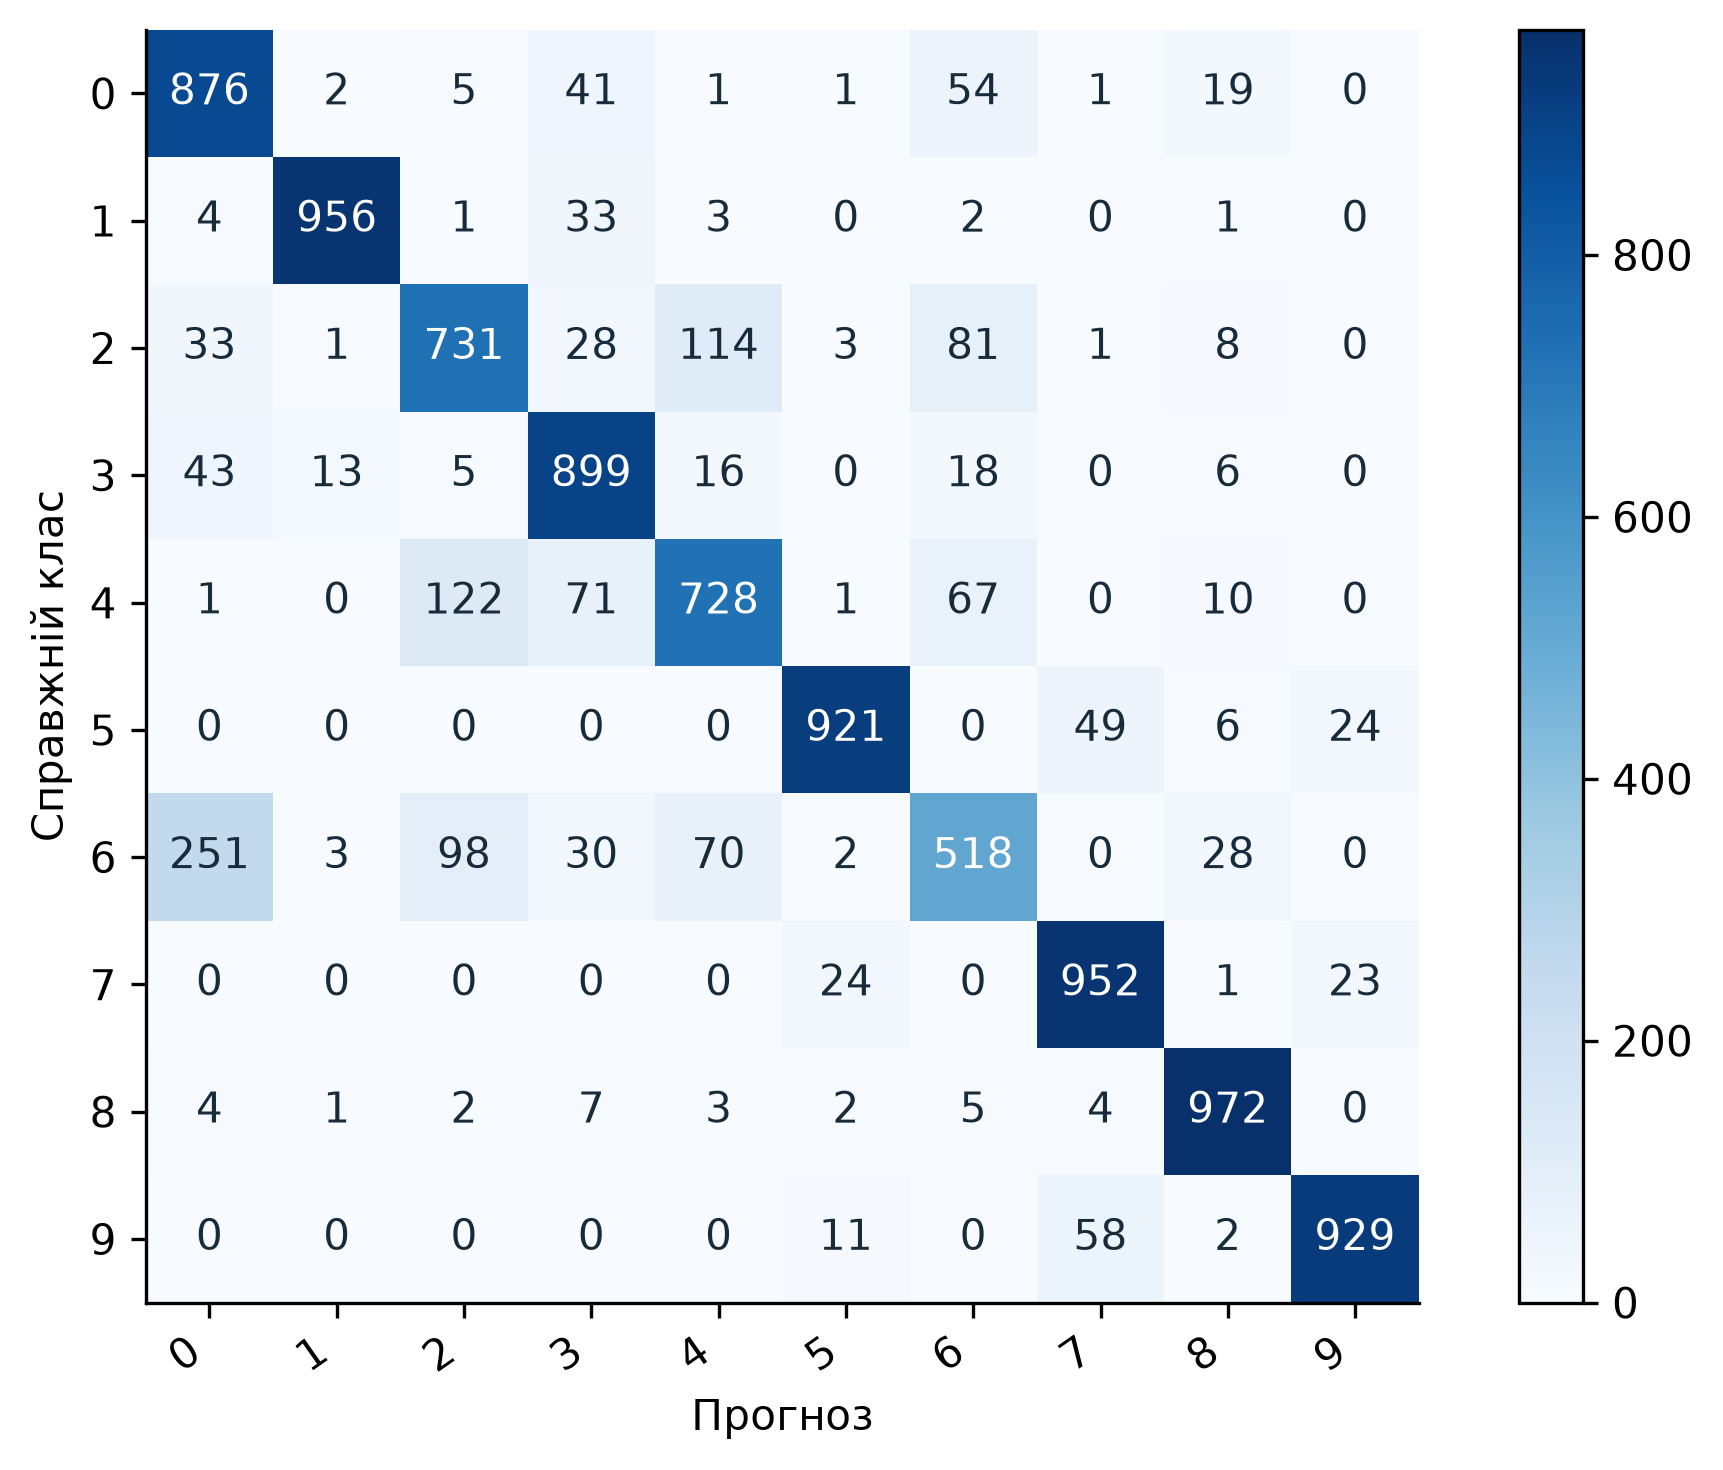

In [27]:
display(Image(filename=str(ROOT / 'lab_05' / 'results' / 'test_confusion.png')))

## Висновки

In [28]:
for text in conclusions(5, R):
    print(text)

Виконав 13 контрольованих експериментів із мережею 784-64-48-32-10. Найменшу фінальну Validation CE отримала конфігурація Baseline: validation accuracy=0,8597. Її Test accuracy=0,8482.
Максимальна відносна похибка чисельної перевірки градієнтів 2.3e-09; відновлення ваг дало максимальну різницю ймовірностей 0.0. Сильніша регуляризація в цій постановці часто погіршувала результат; частка малих ваг і кількість мертвих нейронів не є взаємозамінними показниками.


## Джерела

Xiao H., Rasul K., Vollgraf R. Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist